# 04 — Modern Models and Comparative Diagnostics

**Question.** Do stronger probability models and established admission policies improve the measured cost–secret-residency trade-off beyond the simple baselines? Notebook 03 found no aggregate speed advantage for Logistic over Fixed TTL, despite useful cyclic-thrashing behaviour. This notebook tests that limitation rather than assuming a proposed architecture is necessary.

MacBook performs training and analysis in these visible cells. Real ML-KEM operations and online predictor costs are measured on Raspberry Pi 5. The final test remains unavailable until the complete method and protocol are frozen.

In [1]:
from pathlib import Path
import hashlib, json, os, re, platform
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown, HTML
# Resolve the repository root from either the root directory or notebooks/.
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "notebooks").is_dir() and (p / "dataset").is_dir()), None)
assert ROOT is not None, "run this notebook from inside the repository"
def relocate(rel):
    """Map a path recorded at acquisition time (original project layout) onto this repository's layout."""
    rel = str(rel)
    for old, new in (("Dataset/Raw/PiExperiments/", "dataset/raw/"), ("Dataset/Raw/", "dataset/raw/"), ("Raw/", "raw/"),
                     ("Dataset/Interim/", "dataset/interim/"), ("Dataset/Processed/", "dataset/processed/"),
                     ("Dataset/Splits/", "dataset/splits/"), ("Dataset/Provenance/", "dataset/provenance/"),
                     ("Artifacts/Models/", "support/models/"), ("Artifacts/Binaries/", "support/binaries/"),
                     ("Configs/", "support/configs/"), ("Manifests/", "support/manifests/"), ("Native/", "support/native/"),
                     ("Reports/CoreCalibration/", "support/calibration/"), ("Tables/", "artifacts/"), ("Figures/", "figures/")):
        if rel.startswith(old):
            return new + rel[len(old):]
    return rel
def acquisition_path(path):
    """Inverse of relocate: a repository path written in the acquisition-time layout used inside frozen records."""
    path = Path(path)
    rel = str(path.resolve().relative_to(ROOT)) if path.is_absolute() else str(path)
    for old, new in (("dataset/raw/MLKEM_TestVectors/", "Dataset/Raw/MLKEM_TestVectors/"), ("dataset/raw/IoT23/", "Dataset/Raw/IoT23/"),
                     ("dataset/raw/", "Dataset/Raw/PiExperiments/"), ("dataset/interim/", "Dataset/Interim/"),
                     ("dataset/processed/", "Dataset/Processed/"), ("dataset/splits/", "Dataset/Splits/"),
                     ("dataset/provenance/", "Dataset/Provenance/"), ("support/models/", "Artifacts/Models/"),
                     ("support/binaries/", "Artifacts/Binaries/"), ("support/configs/", "Configs/"), ("support/manifests/", "Manifests/"),
                     ("support/native/", "Native/"), ("support/calibration/", "Reports/CoreCalibration/"),
                     ("artifacts/", "Tables/"), ("figures/", "Figures/")):
        if rel.startswith(old):
            return new + rel[len(old):]
    return rel
from datetime import datetime, timezone
REPLAY_DIR = ROOT/"artifacts/replays/04"/datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
for subdir in ["Tables","Figures","Interim","Configs","Artifacts/Models"]:
    (REPLAY_DIR/subdir).mkdir(parents=True,exist_ok=False)
DATA = ROOT / "dataset"
RAW = DATA / "raw"
TABLES, FIGURES = REPLAY_DIR/"Tables", REPLAY_DIR/"Figures"
for p in (TABLES, FIGURES, DATA / "interim", DATA / "splits"):
    p.mkdir(exist_ok=True)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 180)
try:
    font_manager.findfont("Times New Roman", fallback_to_default=False); FONT_FAMILY = "Times New Roman"
except ValueError:
    FONT_FAMILY = "serif"  # the published figures use Times New Roman; any serif font keeps the layout
mpl.rcParams.update({"font.family": FONT_FAMILY, "font.size":18,
    "axes.titlesize":20,"axes.labelsize":20,"xtick.labelsize":18,
    "ytick.labelsize":18,"legend.fontsize":18,"figure.dpi":350,
    "savefig.dpi":350,"axes.unicode_minus":True,"pdf.fonttype":42})
COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#4D4D4D"]

def save_table(frame, name, *, show=True, exclude=(), columns=None):
    frame.to_csv(TABLES / f"04_{name}.csv", index=True)
    frame.to_latex(TABLES / f"04_{name}.tex", index=True, float_format="%.3f")
    if show:
        visible = frame.loc[:, columns] if columns is not None else frame.drop(columns=list(exclude))
        display(visible)
def save_figure(fig, name, source):
    # Compact physical canvas, unchanged 18/20 pt text. Wrap instead of shrinking.
    import textwrap
    for axis in fig.axes:
        if axis.get_title():
            axis.set_title(textwrap.fill(axis.get_title().replace("\n", " "), width=max(32, int(fig.get_figwidth()*5))))
        label=axis.get_xlabel()
        if label and len(label)>44:
            axis.set_xlabel(textwrap.fill(label.replace("\n", " "),width=44))
    fig.set_layout_engine("constrained")
    fig.savefig(FIGURES / f"04_{name}.png", dpi=350, bbox_inches="tight")
    fig.savefig(FIGURES / f"04_{name}.pdf", dpi=350, bbox_inches="tight")
    source.to_csv(TABLES / f"04_{name}_source.csv", index=False)
    plt.show()
    plt.close(fig)

from collections import deque
from sklearn.feature_selection import mutual_info_classif
from scipy.stats import spearmanr

import subprocess, shlex, time, io, joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, average_precision_score, roc_auc_score, confusion_matrix
from sklearn.calibration import calibration_curve
ARTIFACTS=REPLAY_DIR/"Artifacts"; (ARTIFACTS/"Models").mkdir(parents=True,exist_ok=True)

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone
from threadpoolctl import threadpool_limits
import sklearn
assert sklearn.__version__.startswith("1.8."), "Revalidate native tree export after a scikit-learn version change"


In [2]:
# Verify the archived native campaign and the pinned sources before any analysis.
_binding_path=ROOT/'support/manifests/NotebookReplays/03_04_guard_83e5e1f10c6bab6b/bindings.json'
assert hashlib.sha256(_binding_path.read_bytes()).hexdigest()=='ca419e5bc33f0b9baebb4b788daeb7eb5db8d02e54f257fb7e032f4dd396913c'
REPLAY_BINDINGS=json.loads(_binding_path.read_text())
for rel,digest in REPLAY_BINDINGS['files'].items():
    path=(ROOT/relocate(rel)).resolve();assert path.is_relative_to(ROOT)
    assert hashlib.sha256(path.read_bytes()).hexdigest()==digest,rel
collection=ROOT/relocate(REPLAY_BINDINGS['campaigns']['04'])
assert (collection/'SHA256SUMS').is_file(), 'archived native collection is missing'
for line in (collection/'SHA256SUMS').read_text().splitlines():
    digest,name=line.split(maxsplit=1);path=(collection/name).resolve()
    assert path.is_relative_to(collection.resolve()) and hashlib.sha256(path.read_bytes()).hexdigest()==digest,name
CLOSED_NATIVE_REPLAY=True
def check_pinned_native_text(name,text):
    path=ROOT/'support/native'/name
    assert acquisition_path(path) in REPLAY_BINDINGS['files']
    assert text.encode()==path.read_bytes(), 'refitted model differs from the archived native model'


## 04.1. Competitors and fixed search budget

Random Forest tests nonlinear feature interactions with bagging; histogram gradient boosting tests sequential residual correction. Both receive **three prespecified configurations and the same three purged forward folds**. Early stopping is disabled to avoid an implicit random validation split. No deep network or additional boosting package is introduced without a specific unresolved need. The best configuration minimizes mean session Brier loss across folds. Development data diagnose transfer to new sessions; final evaluation is separate.

For native cache comparison, TinyLFU admission is motivated by its established frequency sketch, ageing and admission-vs-eviction distinction. Its bounded-TTL variant must be labelled explicitly, rather than presented as a new algorithm or an exact reproduction of unconstrained published benchmarks. See Einziger, Friedman and Manes, TinyLFU, Sections 3.2–3.4 (https://arxiv.org/abs/1512.00727). Strong native cost-aware/TTL baselines are considered alongside predictors. Source and algorithmic differences will be recorded before measurement.

In [3]:
for manifest_name in ["02_derived_hashes.json","03_derived_hashes.json"]:
    for rel,h in json.loads((ROOT/"support/manifests/NotebookRuns"/manifest_name).read_text()).items():
        assert hashlib.sha256((ROOT/relocate(rel)).read_bytes()).hexdigest()==h,rel
spec=json.loads((ROOT/"support/configs/feature_definition.json").read_text());FEATURES=spec["features"]
f=pd.read_parquet(DATA/"processed/causal_features_v2.parquet")
f=f.loc[f.eligible].set_index("row_id",drop=False)
train=f.loc[f.split.eq("train")];dev=f.loc[f.split.eq("development")]
folds=pd.read_parquet(DATA/"splits/inner_purged_folds_v1.parquet")
assert set(train.session_id).isdisjoint(dev.session_id) and set(f.split)=={"train","development"}
BASE_DEV=pd.read_parquet(ROOT/"support/models/baseline_development_predictions.parquet")
BASE_OOF=pd.read_parquet(ROOT/"support/models/baseline_oof.parquet")
SEARCH={
 "RF":[{"n_estimators":64,"max_depth":6,"min_samples_leaf":40},{"n_estimators":96,"max_depth":10,"min_samples_leaf":30},{"n_estimators":128,"max_depth":14,"min_samples_leaf":20}],
 "HGB":[{"max_iter":64,"max_leaf_nodes":7,"learning_rate":.1,"min_samples_leaf":40},{"max_iter":96,"max_leaf_nodes":15,"learning_rate":.08,"min_samples_leaf":30},{"max_iter":144,"max_leaf_nodes":15,"learning_rate":.05,"min_samples_leaf":20}]}
search_spec={"search":SEARCH,"selection":"mean of session Brier loss across the same 3 purged folds","seed":2404,"threads":2,"HGB_early_stopping":False,"test_used":False}
(REPLAY_DIR/"Configs/modern_model_search.json").write_text(json.dumps(search_spec,indent=2)+"\n")
save_table(pd.DataFrame([{"Family":family,"Candidate":i,**cfg} for family,configs in SEARCH.items() for i,cfg in enumerate(configs)]).set_index(["Family","Candidate"]),"search_space")

n_estimators  max_depth  min_samples_leaf  max_iter  max_leaf_nodes  learning_rate
Family Candidate                                                                                    
RF     0                  64.0        6.0                40       NaN             NaN            NaN
       1                  96.0       10.0                30       NaN             NaN            NaN
       2                 128.0       14.0                20       NaN             NaN            NaN
HGB    0                   NaN        NaN                40      64.0             7.0           0.10
       1                   NaN        NaN                30      96.0            15.0           0.08
       2                   NaN        NaN                20     144.0            15.0           0.05

In [4]:
def metrics(q,probability):
    y=q.y10.astype(int).to_numpy();p=np.clip(np.asarray(probability),1e-9,1-1e-9)
    session_loss=pd.DataFrame({"session_id":q.session_id.to_numpy(),"loss":(p-y)**2}).groupby("session_id").loss.mean()
    return {"Rows":len(y),"Sessions":q.session_id.nunique(),"Brier_session_mean":session_loss.mean(),"Brier_pooled":brier_score_loss(y,p),"Log_loss":log_loss(y,p,labels=[0,1]),"PR_AUC_AP":average_precision_score(y,p),"ROC_AUC":roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan}

def make_model(family,config):
    if family=="RF":return RandomForestClassifier(**config,n_jobs=2,random_state=2404,max_features="sqrt")
    return HistGradientBoostingClassifier(**config,early_stopping=False,l2_regularization=1.,random_state=2404)
modern_oof_parts=[];search_records=[]
for family,configs in SEARCH.items():
    for candidate,cfg in enumerate(configs):
        for fold in [1,2,3]:
            tr=f.loc[folds.loc[folds.fold.eq(fold)&folds.role.eq("train"),"row_id"]]
            va=f.loc[folds.loc[folds.fold.eq(fold)&folds.role.eq("validation"),"row_id"]]
            assert set(tr.row_id).isdisjoint(va.row_id)
            model=make_model(family,cfg);begin=time.perf_counter()
            with threadpool_limits(limits=2):model.fit(tr[FEATURES],tr.y10.astype(int));p=model.predict_proba(va[FEATURES])[:,1]
            elapsed=time.perf_counter()-begin
            search_records.append({"Family":family,"Candidate":candidate,"Fold":fold,"Fit_and_predict_s_Mac":elapsed,**metrics(va,p)})
            q=va[["row_id","session_id","workload_id","schedule_ms","y10"]].copy();q["model"]=family;q["candidate"]=candidate;q["fold"]=fold;q["probability"]=p;modern_oof_parts.append(q)
search_results=pd.DataFrame(search_records)
selection=search_results.groupby(["Family","Candidate"]).Brier_session_mean.agg(["mean","std"])
save_table(selection,"model_selection")
search_results.to_csv(TABLES/"04_search_all_folds.csv",index=False)
best={family:int(selection.loc[family]["mean"].idxmin()) for family in SEARCH}
modern_oof=pd.concat(modern_oof_parts,ignore_index=True)
modern_oof=modern_oof.loc[[candidate==best[family] for family,candidate in zip(modern_oof.model,modern_oof.candidate)]].copy()
modern_models={};modern_dev_parts=[];model_fit_records=[]
for family,candidate in best.items():
    model=make_model(family,SEARCH[family][candidate]);begin=time.perf_counter()
    with threadpool_limits(limits=2):model.fit(train[FEATURES],train.y10.astype(int));p=model.predict_proba(dev[FEATURES])[:,1]
    model_fit_records.append({"Model":family,"Training_seconds_Mac":time.perf_counter()-begin,"Candidate":candidate})
    modern_models[family]=model
    q=dev[["row_id","session_id","workload_id","schedule_ms","y10"]].copy();q["model"]=family;q["probability"]=p;modern_dev_parts.append(q)
    joblib.dump(model,ARTIFACTS/"Models"/f"{family.lower()}.joblib")
modern_dev=pd.concat(modern_dev_parts,ignore_index=True)
modern_oof.to_parquet(ARTIFACTS/"Models/modern_oof.parquet",index=False)
modern_dev.to_parquet(ARTIFACTS/"Models/modern_development_predictions.parquet",index=False)
save_table(pd.DataFrame(model_fit_records).set_index("Model"),"training_resources")
save_table(pd.DataFrame([{ "Model":name,**metrics(q,q.probability)} for name,q in pd.concat([BASE_DEV,modern_dev]).groupby("model")]).set_index("Model"),"development_prediction_metrics", show=False)

mean       std
Family Candidate                    
HGB    0          0.121780  0.011922
       1          0.121730  0.012980
       2          0.121592  0.012926
RF     0          0.122703  0.011488
       1          0.121852  0.012219
       2          0.121929  0.012576

,Training_seconds_Mac,Candidate
Model,,
RF,1.321998,1
HGB,0.644665,2


## 04.2. Calibration without final-test access

Platt calibration is fitted only to the selected model's training OOF predictions and labels, then evaluated on independent development sessions. OOF-based hyperparameter selection means those calibration inputs are not an unbiased final performance estimate. For each model, calibrated or raw probabilities are selected using development Brier loss; that is explicitly another development decision. Neither calibration fit nor selection reads final-test labels.

,Calibrated_Brier,Use_calibration,Slope,Intercept
Model,,,,
RF,0.118709,False,1.024919,-0.045644
HGB,0.117944,False,1.014965,-0.046612


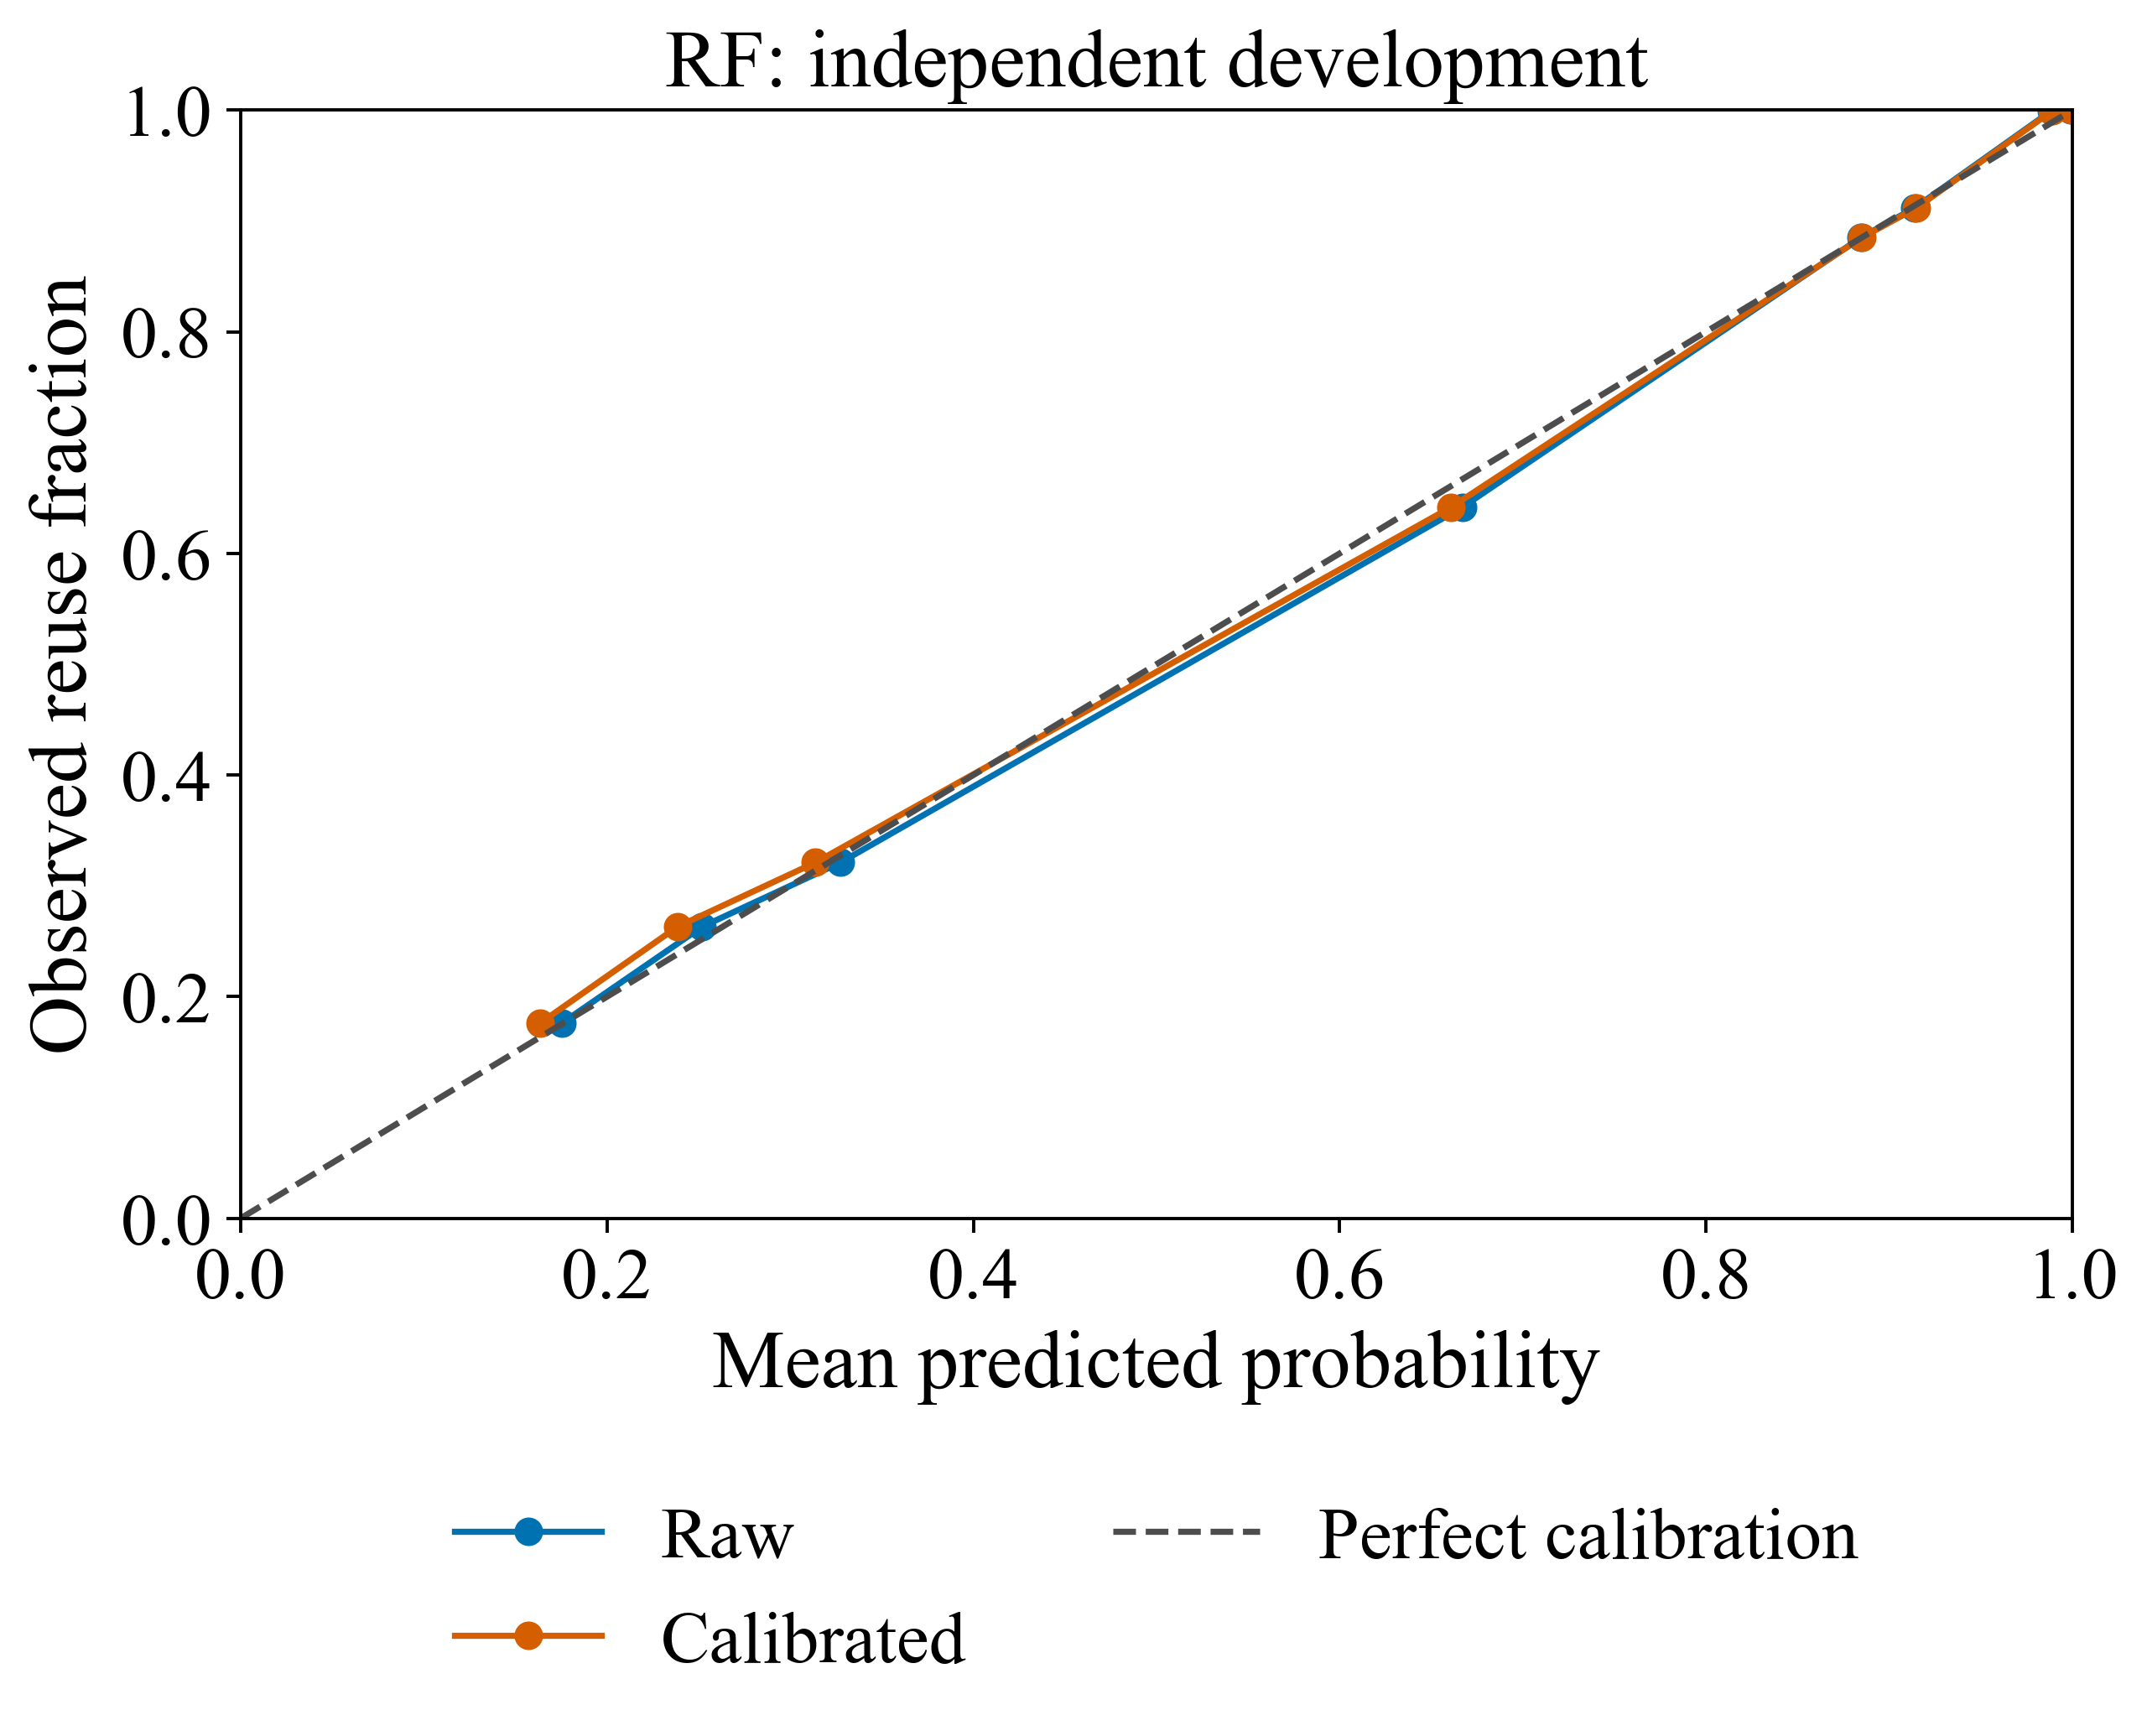

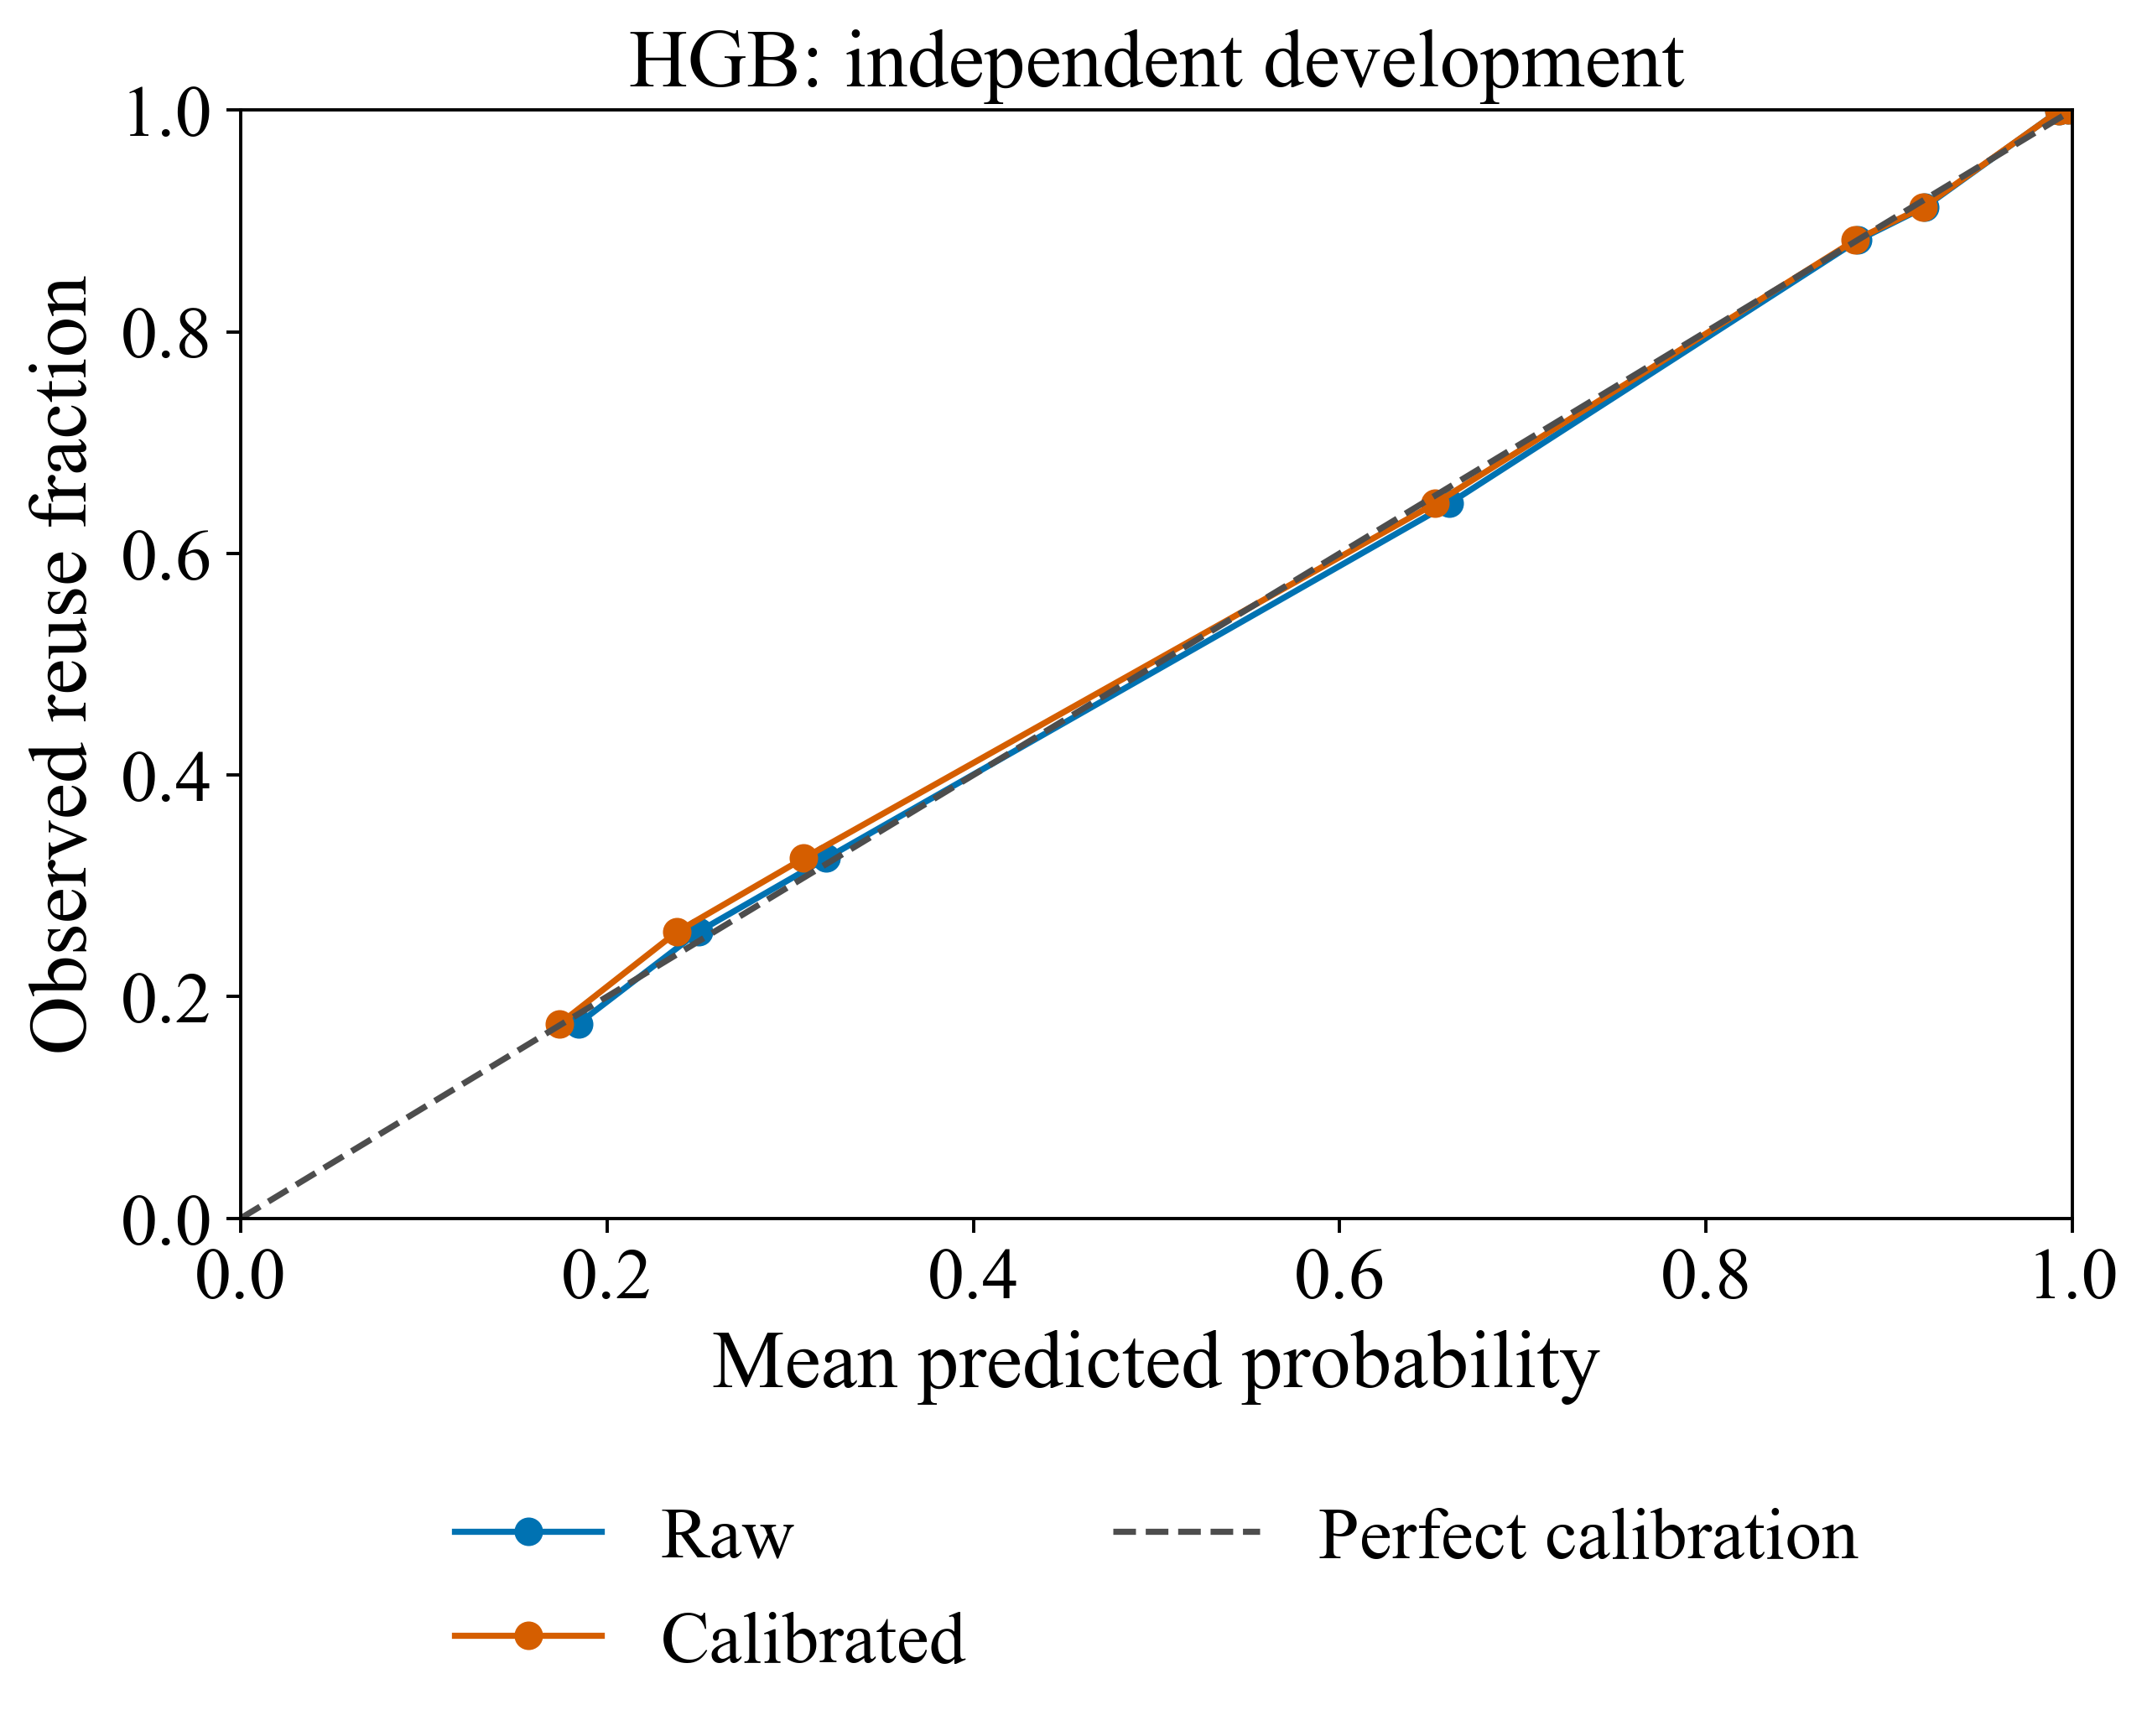

In [5]:
def logit_feature(p):
    p=np.clip(np.asarray(p),1e-6,1-1e-6);return np.log(p/(1-p)).reshape(-1,1)
calibrators={};calibration_records=[];calibrated_parts=[];calibration_spec={}
for family in ["RF","HGB"]:
    q=modern_oof.loc[modern_oof.model.eq(family)]
    calibrator=LogisticRegression(C=10.,max_iter=1000,random_state=2404).fit(logit_feature(q.probability),q.y10.astype(int))
    calibrators[family]=calibrator
    raw=modern_dev.loc[modern_dev.model.eq(family)].copy()
    calibrated=raw.copy();calibrated["probability"]=calibrator.predict_proba(logit_feature(raw.probability))[:,1];calibrated["model"]=family+" calibrated";calibrated_parts.append(calibrated)
    mraw=metrics(raw,raw.probability);mcal=metrics(calibrated,calibrated.probability)
    use=mcal["Brier_session_mean"]<mraw["Brier_session_mean"]
    calibration_spec[family]={"apply":bool(use),"slope":float(calibrator.coef_[0,0]),"intercept":float(calibrator.intercept_[0]),"clip":1e-6,"selection_split":"development","fit_split":"train OOF"}
    calibration_records.append({"Model":family,"Raw_Brier":mraw["Brier_session_mean"],"Calibrated_Brier":mcal["Brier_session_mean"],"Use_calibration":use,"Slope":calibrator.coef_[0,0],"Intercept":calibrator.intercept_[0]})
calibrated_dev=pd.concat(calibrated_parts,ignore_index=True)
save_table(pd.DataFrame(calibration_records).set_index("Model"),"calibration_selection", exclude=["Raw_Brier"])
(REPLAY_DIR/"Configs/modern_calibration.json").write_text(json.dumps(calibration_spec,indent=2)+"\n")
calibration_plot_rows=[]
for family in ["RF","HGB"]:
    fig,ax=plt.subplots(figsize=(7.2,5.8),layout="constrained")
    family_plot_rows=[]
    for name,part,color in [("Raw",modern_dev.loc[modern_dev.model.eq(family)],COLORS[0]),("Calibrated",calibrated_dev.loc[calibrated_dev.model.eq(family+" calibrated")],COLORS[1])]:
        observed,predicted=calibration_curve(part.y10.astype(int),part.probability,n_bins=8,strategy="quantile")
        ax.plot(predicted,observed,marker="o",label=name,color=color)
        family_plot_rows.extend({"Model":family,"Version":name,"Predicted":x,"Observed":y} for x,y in zip(predicted,observed))
    ax.plot([0,1],[0,1],"--",color=COLORS[4],label="Perfect calibration")
    ax.set(xlabel="Mean predicted probability",ylabel="Observed reuse fraction",xlim=(0,1),ylim=(0,1),title=family+": independent development")
    ax.legend(loc="upper center",bbox_to_anchor=(.5,-.2),ncol=2,frameon=False)
    calibration_plot_rows.extend(family_plot_rows)
    save_figure(fig,"calibration_"+family.lower(),pd.DataFrame(family_plot_rows))
pd.DataFrame(calibration_plot_rows).to_csv(TABLES/"04_calibration_source.csv",index=False)

## 04.3. Regime errors and complementarity

Squared probability errors are compared on exactly aligned development requests. A low error correlation alone does not establish that an ensemble will help: both predictive loss and full native execution cost must improve under the intended objective. Regime matrices retain all values, including negative/neutral findings.

,Rows,Sessions,Brier_pooled,Log_loss,PR_AUC_AP,ROC_AUC
Model,,,,,,
EWMA,25610,30,0.165052,1.010931,0.887995,0.840953
Frequency,25610,30,0.147284,0.927561,0.901756,0.862248
HGB,25610,30,0.118114,0.366143,0.948337,0.898736
Logistic,25610,30,0.136060,0.436126,0.917396,0.869838
RF,25610,30,0.118844,0.368386,0.947982,0.897774


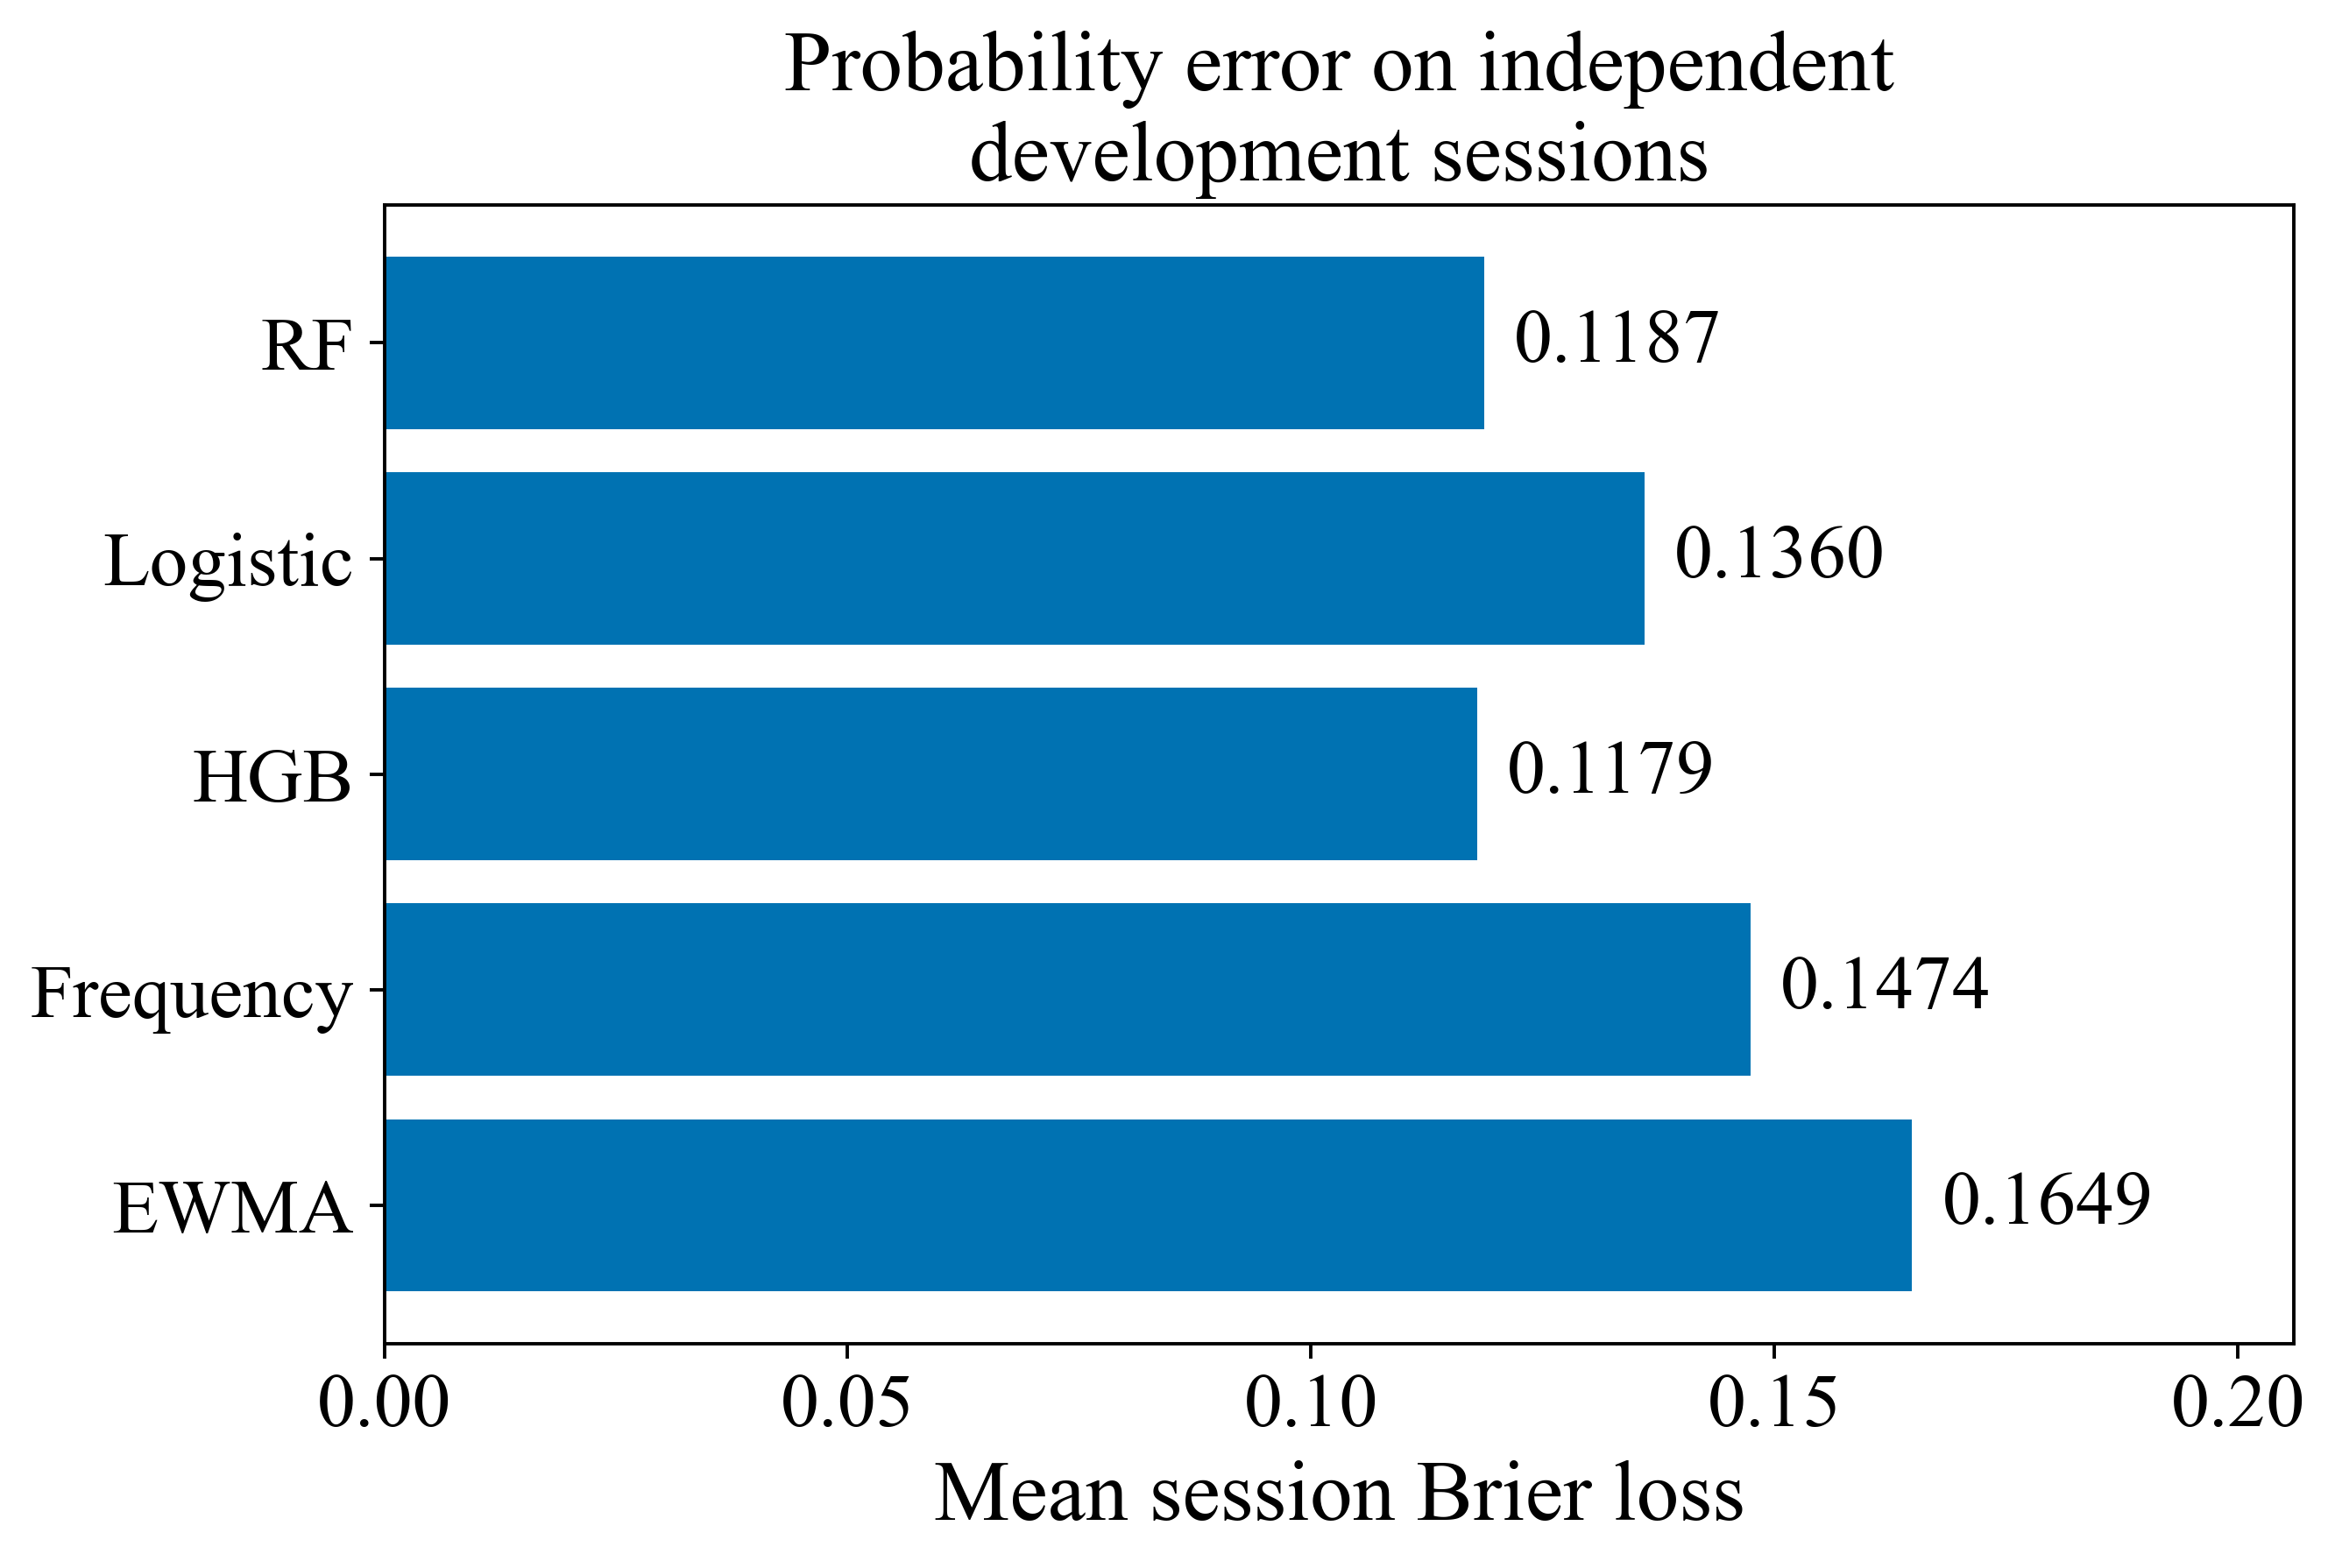

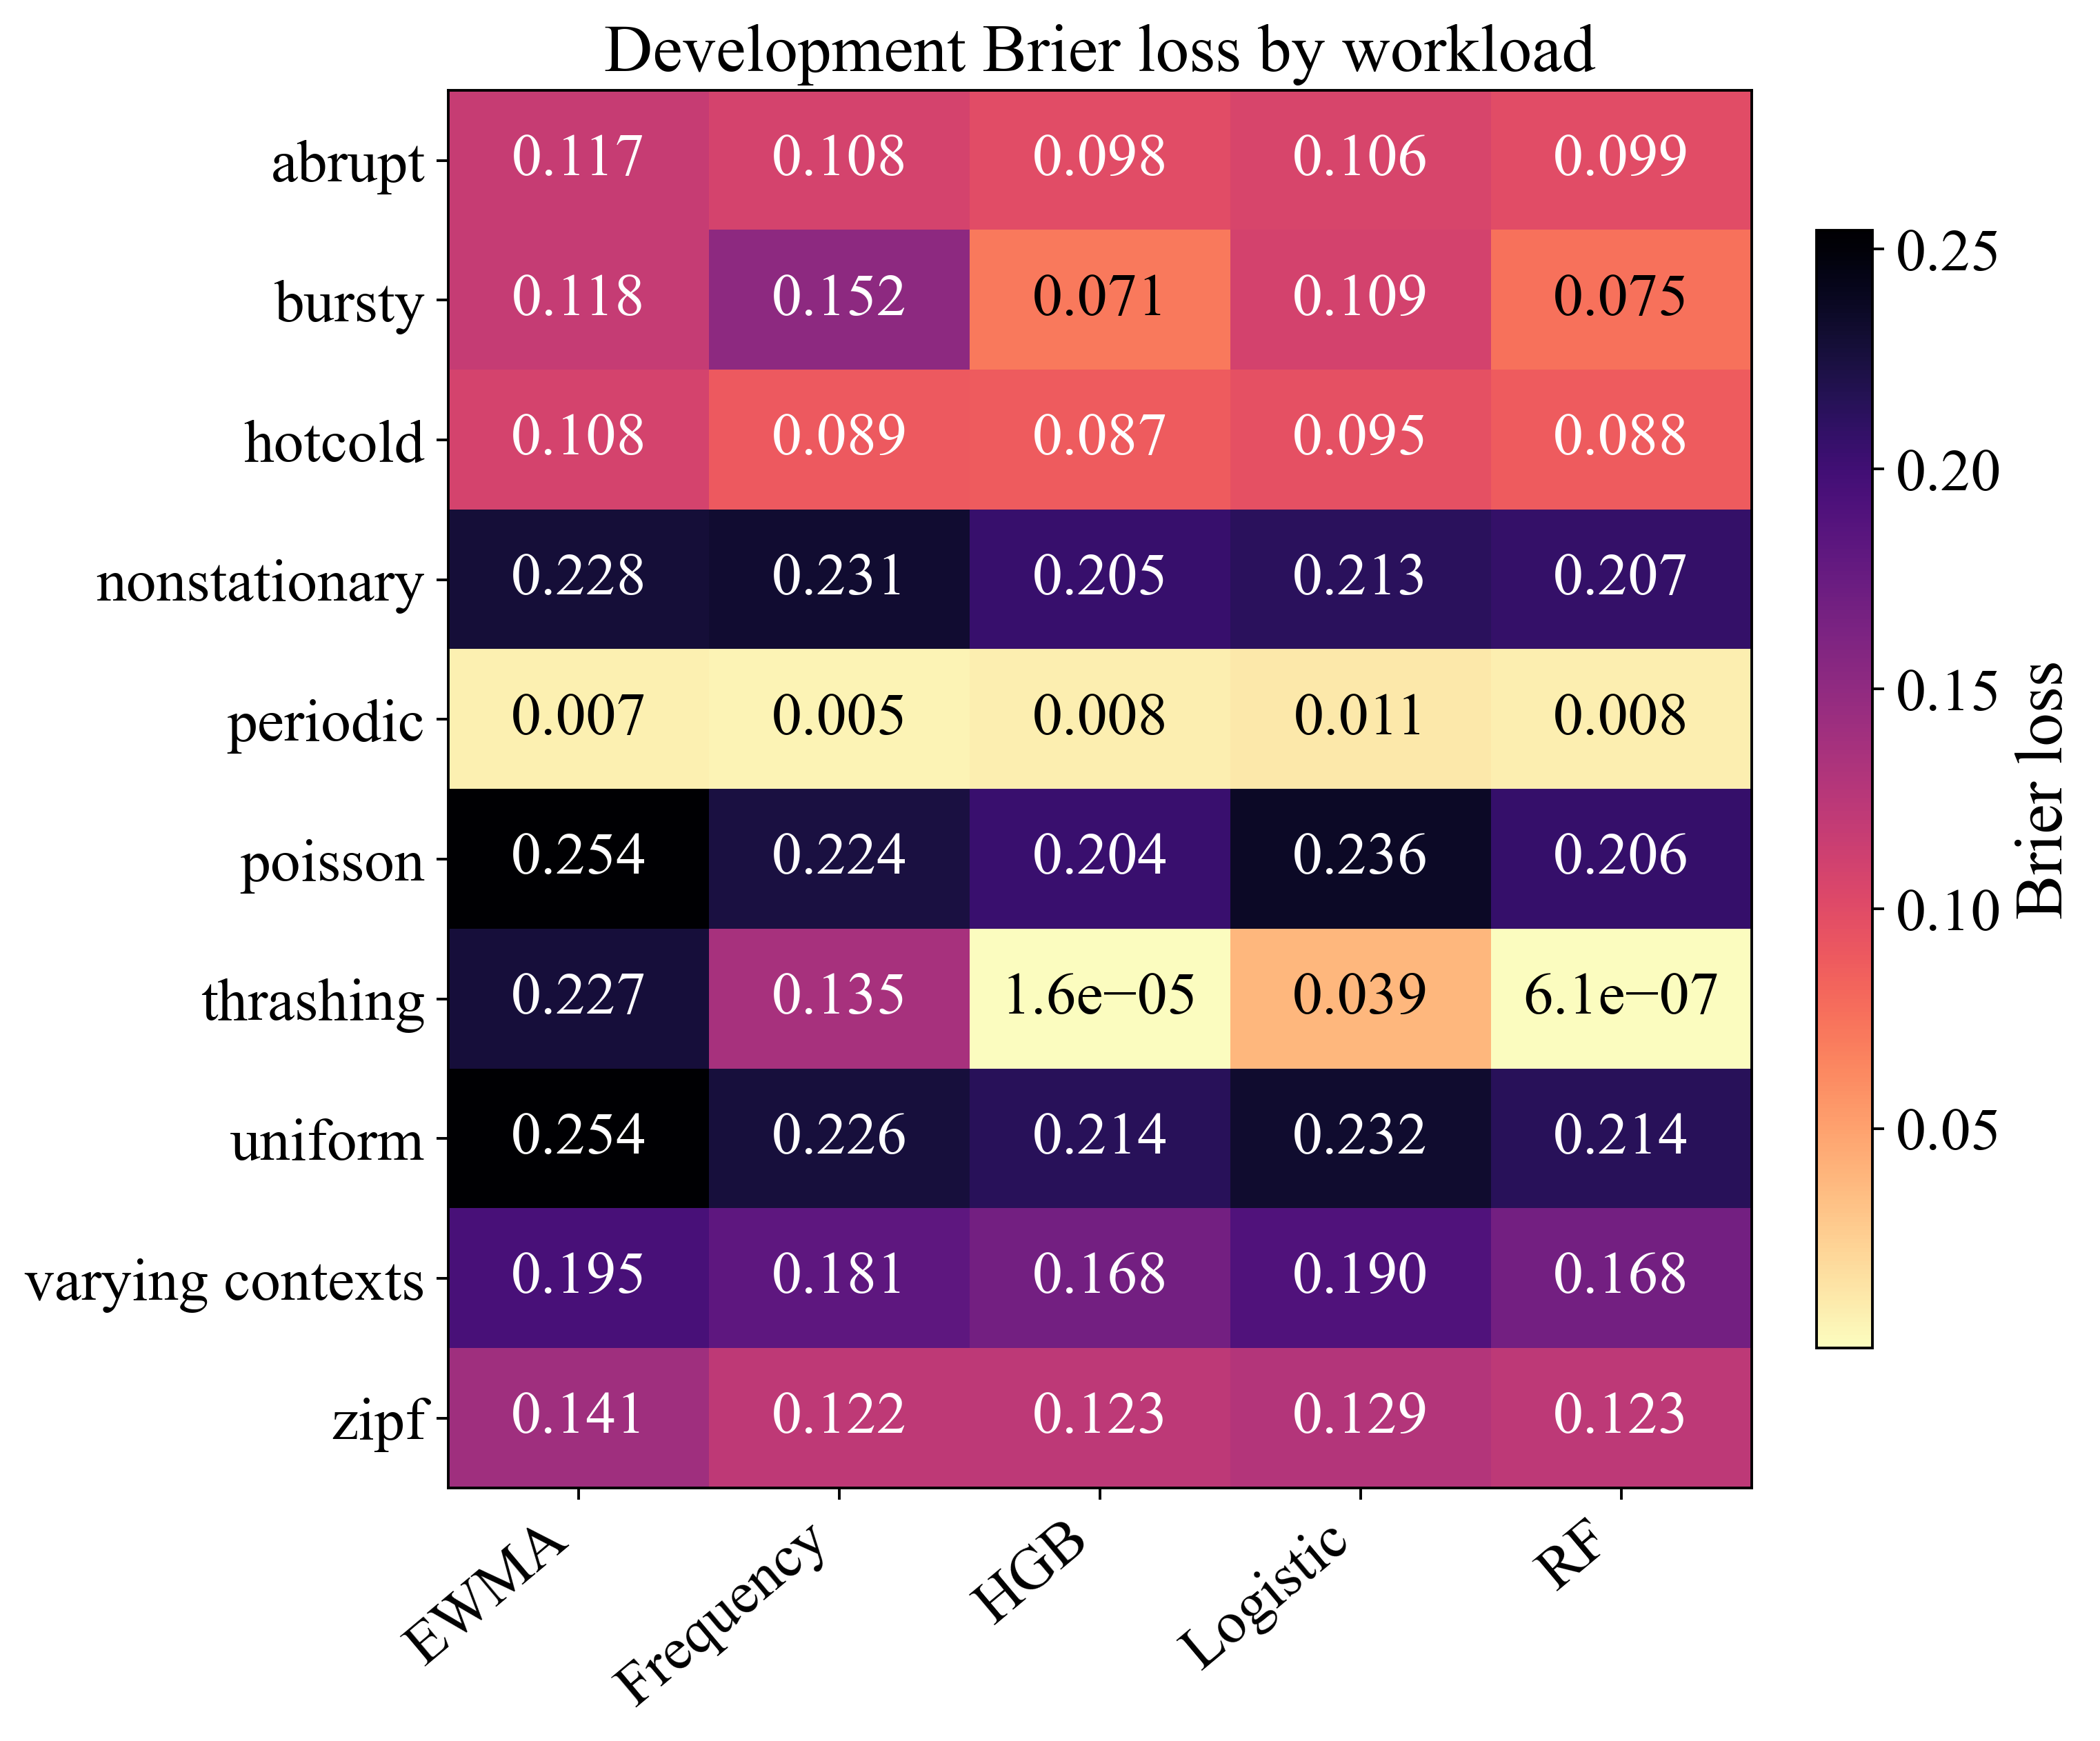

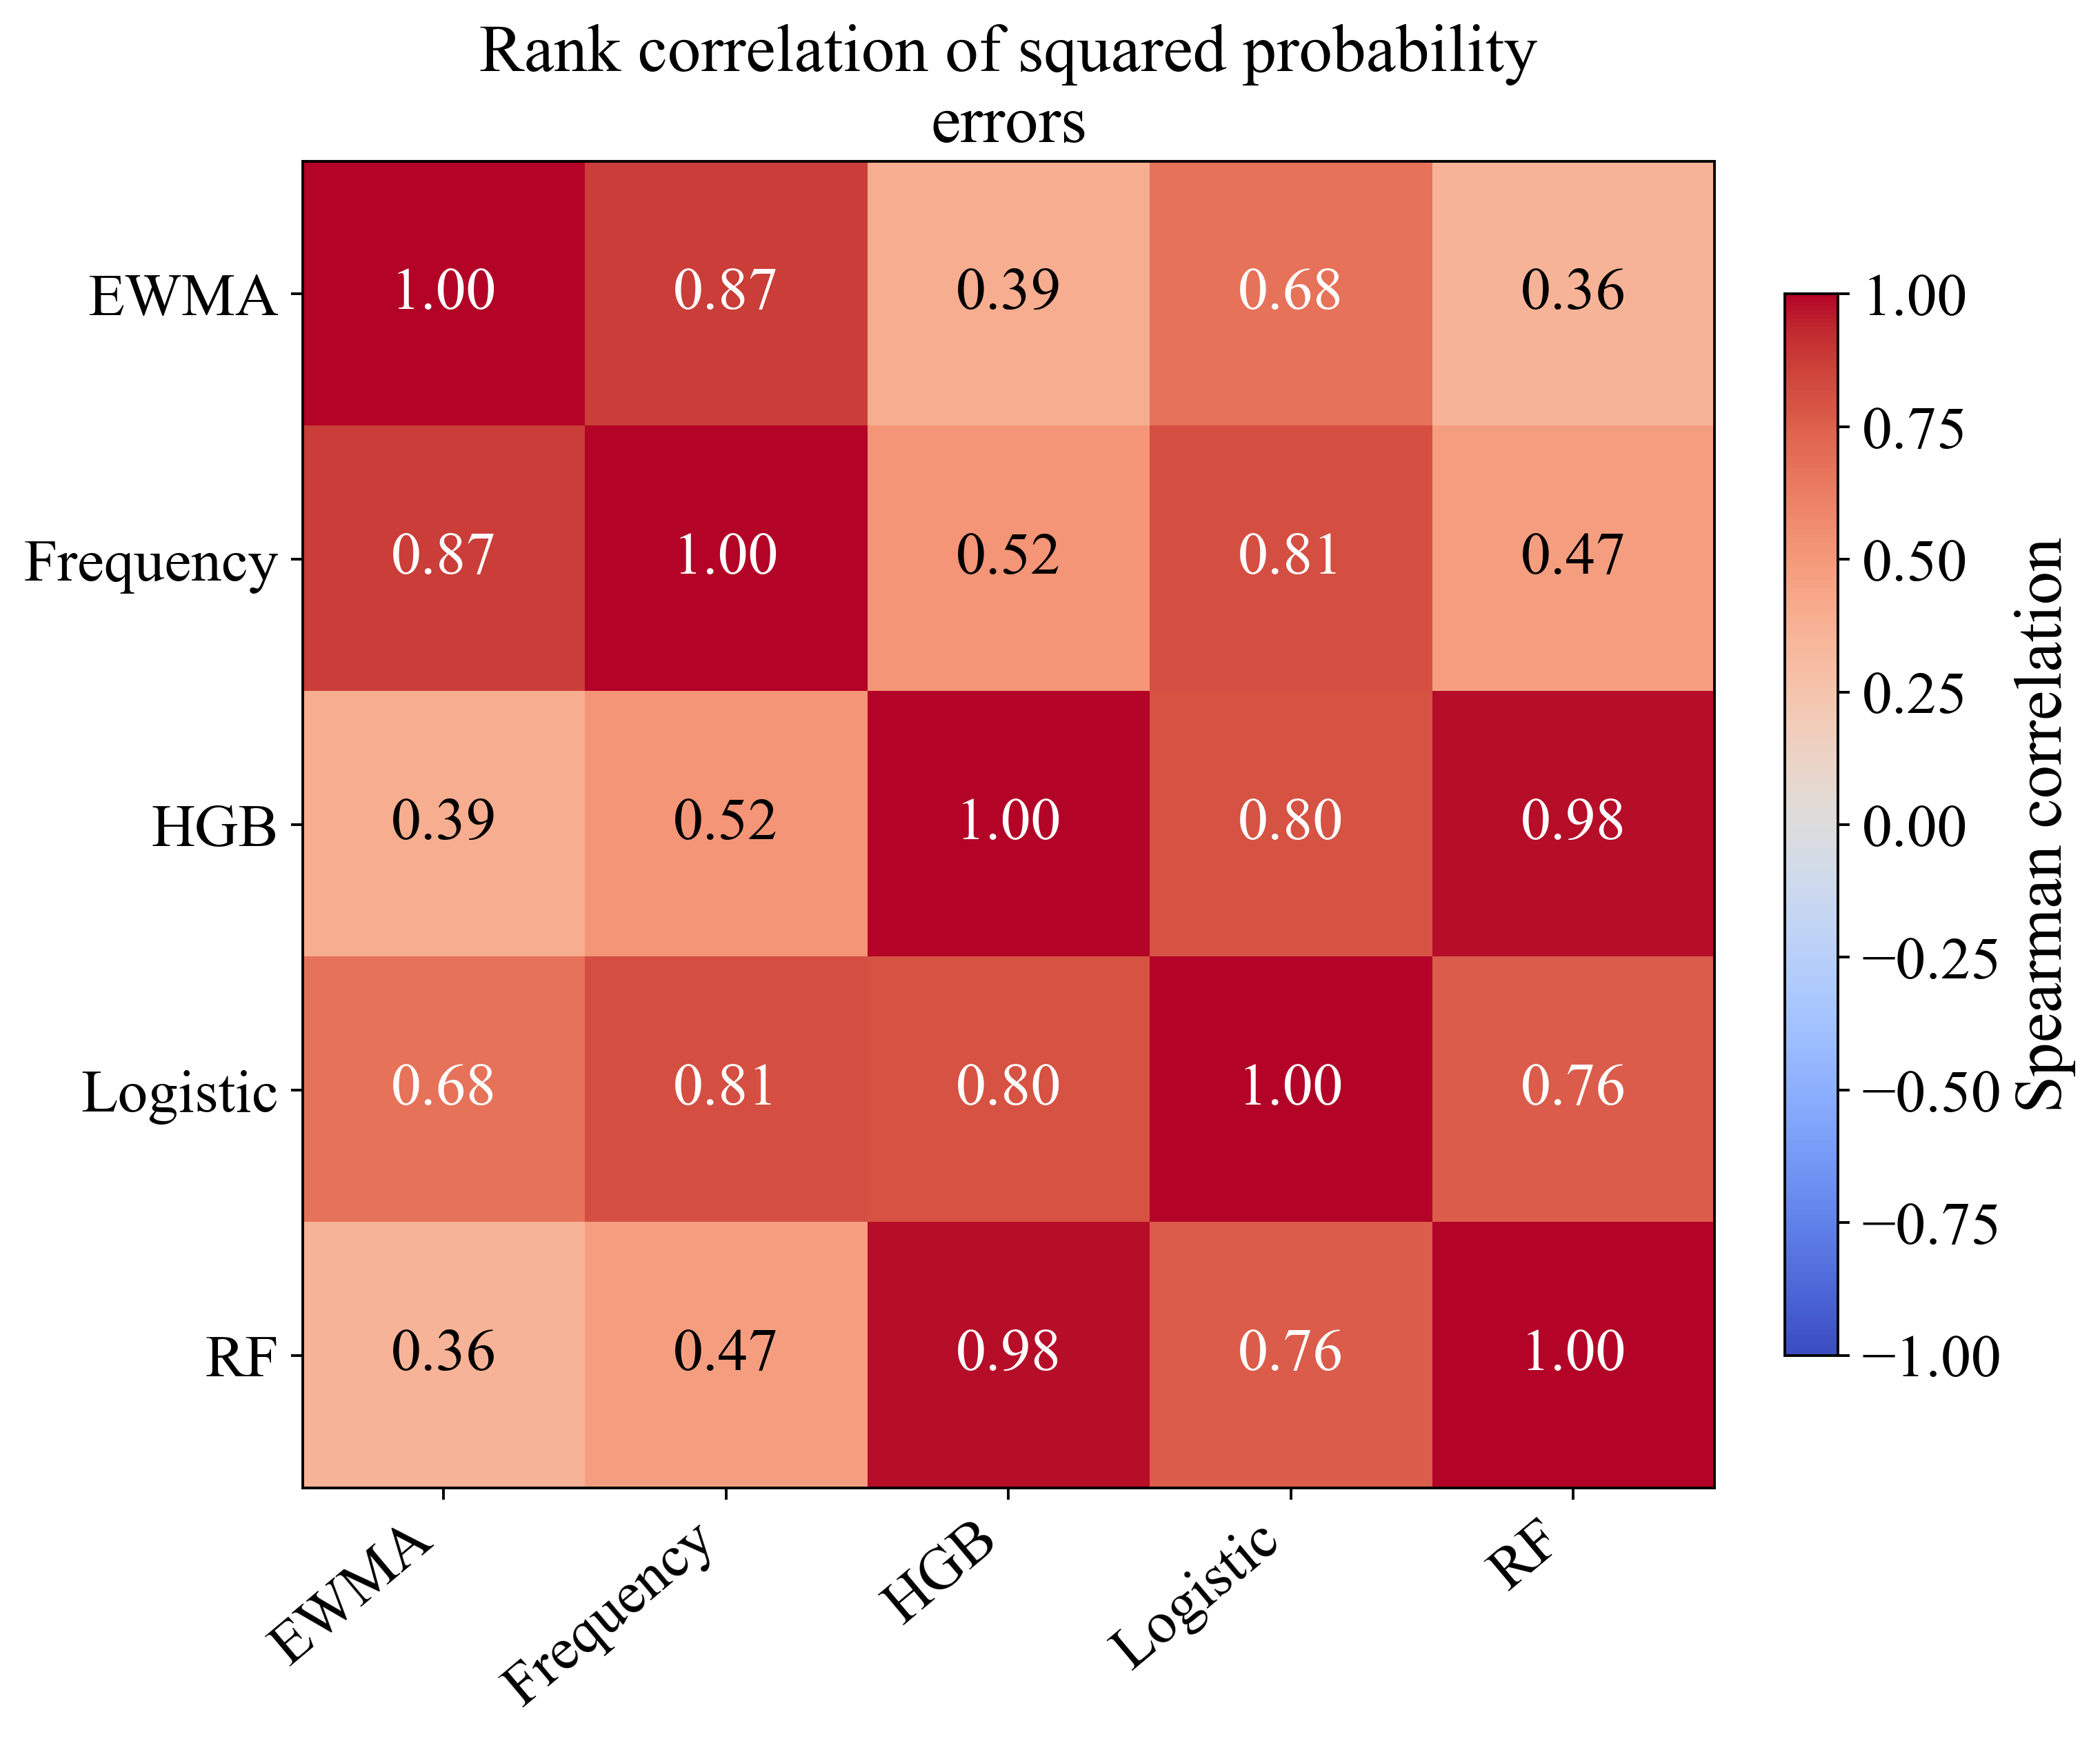

,Fraction_lower_loss_than_Logistic,Mean_Brier_difference_vs_Logistic,Threshold_0.5_disagreement
Model,,,
RF,0.584381,-0.017216,0.094807
HGB,0.591449,-0.017946,0.096525


In [6]:
selected_modern=[]
for family in ["RF","HGB"]:
    use=calibration_spec[family]["apply"]
    q=(calibrated_dev.loc[calibrated_dev.model.eq(family+" calibrated")] if use else modern_dev.loc[modern_dev.model.eq(family)]).copy();q["model"]=family;selected_modern.append(q)
selected_dev=pd.concat([BASE_DEV.loc[BASE_DEV.model.isin(["Frequency","EWMA","Logistic"])],*selected_modern],ignore_index=True)
selected_dev.to_parquet(ARTIFACTS/"Models/selected_modern_development_predictions.parquet",index=False)
selected_scores=pd.DataFrame([{ "Model":name,**metrics(q,q.probability)} for name,q in selected_dev.groupby("model")]).set_index("Model")
save_table(selected_scores,"selected_development_metrics", exclude=['Brier_session_mean'])
fig,ax=plt.subplots(figsize=(7.5,5.0),layout="constrained")
bars=ax.barh(selected_scores.index,selected_scores.Brier_session_mean,color=COLORS[0]);ax.bar_label(bars,fmt="%.4f",padding=7)
ax.set(xlim=(0,selected_scores.Brier_session_mean.max()*1.25),xlabel="Mean session Brier loss",title="Probability error on independent development sessions")
save_figure(fig,"selected_brier",selected_scores.reset_index())
def heatmap_numeric(frame,title,label,name,fmt=".3f",cmap="viridis",vmin=None,vmax=None):
    values=frame.to_numpy();fig,ax=plt.subplots(figsize=(8.6,7.1),layout="constrained");im=ax.imshow(values,cmap=cmap,aspect="auto",vmin=vmin,vmax=vmax)
    ax.set_xticks(range(len(frame.columns)),frame.columns,rotation=40,ha="right");ax.set_yticks(range(len(frame)),[str(s).replace("_"," ") for s in frame.index]);ax.set_title(title)
    for i in range(len(frame)):
        for j in range(len(frame.columns)):
            v=values[i,j];rgba=im.cmap(im.norm(v));lum=.2126*rgba[0]+.7152*rgba[1]+.0722*rgba[2]
            ax.text(j,i,(format(v,".1e") if 0<abs(v)<.001 else format(v,fmt)).replace("-","−"),ha="center",va="center",color="black" if lum>.55 else "white")
    fig.colorbar(im,ax=ax,label=label,shrink=.8);save_figure(fig,name,frame.rename_axis("Row").reset_index())
regime_rows=[{"Workload":family,"Model":name,**metrics(q,q.probability)} for (family,name),q in selected_dev.groupby(["workload_id","model"])]
regime_brier=pd.DataFrame(regime_rows).pivot(index="Workload",columns="Model",values="Brier_session_mean")
save_table(regime_brier,"regime_brier", show=False);heatmap_numeric(regime_brier,"Development Brier loss by workload","Brier loss","regime_brier_matrix",cmap="magma_r")
probability_matrix=selected_dev.pivot(index="row_id",columns="model",values="probability").sort_index()
labels=dev.loc[probability_matrix.index,"y10"].astype(int)
errors=probability_matrix.sub(labels,axis=0)**2
error_corr=errors.corr(method="spearman")
heatmap_numeric(error_corr,"Rank correlation of squared probability errors","Spearman correlation","error_complementarity",fmt=".2f",cmap="coolwarm",vmin=-1,vmax=1)
comparisons=[]
for family in ["RF","HGB"]:
    delta=errors[family]-errors.Logistic
    comparisons.append({"Model":family,"Fraction_lower_loss_than_Logistic":(delta<0).mean(),"Mean_Brier_difference_vs_Logistic":delta.mean(),"Threshold_0.5_disagreement":((probability_matrix[family]>=.5)!=(probability_matrix.Logistic>=.5)).mean()})
save_table(pd.DataFrame(comparisons).set_index("Model"),"error_complementarity_summary")

**Observed predictive result.** RF selected candidate 1 and HGB candidate 2 using purged training folds. Their development Brier losses were 0.118656 and 0.117906, compared with 0.135993 for Logistic. Platt calibration slightly worsened both scores, so raw probabilities are retained. The controlled thrashing family is almost deterministic and consequently easy to predict; this should not be extrapolated to production traffic. Very small nonzero matrix values use scientific notation rather than displaying misleading rounded zeros.

## 04.4. Exact native tree export and probability parity

The following visible converter exports the fitted numerical decision rules into C. RF inputs are explicitly rounded to float32 to match scikit-learn's tree prediction path. HGB uses its numerical thresholds, already-shrunk leaf contributions and baseline log-odds. The converter is pinned to the installed scikit-learn 1.8 version and rejects categorical nodes. All 25,610 eligible development rows were checked on the Raspberry Pi before the timing comparison. On re-execution the regenerated C rules must be byte-identical to the pinned header, and the parity table is read from the saved summary. This verifies probability translation, not model validity or security.

In [7]:
# Export trained decision rules; no cryptographic secrets are involved.
header=["/* Generated from training-only models by Notebook 04. */", "#ifndef SCAR_MODEL_TREES_H", "#define SCAR_MODEL_TREES_H", "#include <math.h>", "typedef struct {int feature,left,right;double threshold,value;} ScarNode;"]
model_structure=[]
for family in ["RF","HGB"]:
    model=modern_models[family];nodes=[];roots=[]
    if family=="RF":
        for estimator in model.estimators_:
            tree=estimator.tree_;offset=len(nodes);roots.append(offset)
            for j in range(tree.node_count):
                leaf=tree.children_left[j]<0
                value=float(tree.value[j,0,1]/tree.value[j,0].sum())
                nodes.append((-1 if leaf else int(tree.feature[j]),-1 if leaf else offset+int(tree.children_left[j]),-1 if leaf else offset+int(tree.children_right[j]),float(tree.threshold[j]),value))
        base=0.
    else:
        assert model.n_trees_per_iteration_==1
        for predictors in model._predictors:
            array=predictors[0].nodes;assert not array["is_categorical"].any()
            offset=len(nodes);roots.append(offset)
            for row in array:
                leaf=bool(row["is_leaf"])
                nodes.append((-1 if leaf else int(row["feature_idx"]),-1 if leaf else offset+int(row["left"]),-1 if leaf else offset+int(row["right"]),float(row["num_threshold"]),float(row["value"])))
        base=float(model._baseline_prediction[0,0])
    prefix=family.lower()
    header.append(f"static const ScarNode {prefix}_nodes[]={{")
    header.extend("{%d,%d,%d,%.17g,%.17g},"%row for row in nodes);header.append("};")
    header.append(f"static const int {prefix}_roots[]={{"+",".join(map(str,roots))+"};")
    cast="(double)(float)x[n.feature]" if family=="RF" else "x[n.feature]"
    header.append(f"static double predict_{prefix}_raw(const double*x){{double z={base:.17g};")
    header.append(f"for(unsigned t=0;t<sizeof({prefix}_roots)/sizeof(int);t++){{int j={prefix}_roots[t];ScarNode n={prefix}_nodes[j];while(n.feature>=0){{j=({cast}<=n.threshold)?n.left:n.right;n={prefix}_nodes[j];}}z+=n.value;}}")
    header.append(f"return z/{len(roots)}.;}}" if family=="RF" else "return z>=0?1/(1+exp(-z)):exp(z)/(1+exp(z));}")
    cfg=calibration_spec[family]
    if cfg["apply"]:
        header.append(f"static double predict_{prefix}(const double*x){{double p=fmin(1-1e-6,fmax(1e-6,predict_{prefix}_raw(x)));double z={cfg['slope']:.17g}*log(p/(1-p))+({cfg['intercept']:.17g});return z>=0?1/(1+exp(-z)):exp(z)/(1+exp(z));}}")
    else:header.append(f"static double predict_{prefix}(const double*x){{return predict_{prefix}_raw(x);}}")
    model_structure.append({"Model":family,"Trees":len(roots),"Nodes":len(nodes),"Calibration_applied":cfg["apply"],"Joblib_bytes":(ARTIFACTS/"Models"/f"{prefix}.joblib").stat().st_size})
header.append("#endif")
check_pinned_native_text("model_trees.h","\n".join(header)+"\n")
(ARTIFACTS/"Models/modern_selected_config.json").write_text(json.dumps({"features":FEATURES,"models":{family:SEARCH[family][best[family]] for family in best},"calibration":calibration_spec,"sklearn":sklearn.__version__},indent=2)+"\n")
save_table(pd.DataFrame(model_structure).set_index("Model"),"native_model_structure")


,Trees,Nodes,Calibration_applied,Joblib_bytes
Model,,,,
RF,96,33586,False,2727065
HGB,144,4176,False,276432


In [8]:
PI_SETUP=Path(os.environ.get("PI_SETUP_DIR","~/.scar_mlkem_pi")).expanduser()
SSH=["ssh","-F",str(PI_SETUP/"ssh_config"),"-S",str(PI_SETUP/"private/ssh_control"),"-o","BatchMode=yes","nazira-pi"]
REMOTE="/home/research/Nazira_Crystals-Cyber"
def remote(command,input=None,timeout=180):
    assert not CLOSED_NATIVE_REPLAY, "the archived campaign is analysed offline; SSH is not used"
    return subprocess.run(SSH+[command],input=input,check=True,text=True,capture_output=True,timeout=timeout)
def remote_sudo(command):
    auth=json.loads((PI_SETUP/"private/credentials.json").read_text())
    result=remote("sudo -S -p '' sh -c "+shlex.quote(command),input=auth["password"]+"\n");del auth;return result

if CLOSED_NATIVE_REPLAY:
    parity=pd.read_csv(ROOT/"artifacts/04_native_probability_parity.csv").set_index("Model")
    assert set(parity.index)=={"RF","HGB"} and parity.Passed.eq(True).all()
    save_table(parity,"native_probability_parity")
else:
    remote("cat > "+shlex.quote(REMOTE+"/Native/model_trees.h"),input=(ROOT/"support/native/model_trees.h").read_text())
    driver='#include <stdio.h>\n#include "model_trees.h"\nint main(void){double x[11];while(scanf("%lf",&x[0])==1){for(int i=1;i<11;i++)if(scanf("%lf",&x[i])!=1)return 2;printf("%.17g,%.17g\\n",predict_rf(x),predict_hgb(x));}return 0;}\n'
    (ROOT/"support/native/predict_trees_check.c").write_text(driver)
    remote("cat > "+shlex.quote(REMOTE+"/Native/predict_trees_check.c"),input=driver)
    compiled=remote("cd "+shlex.quote(REMOTE)+" && gcc -O3 -std=c11 -Wall -Wextra -Werror Native/predict_trees_check.c -lm -o Native/build/predict_trees_check")
    public_input="\n".join(" ".join(f"{v:.17g}" for v in row) for row in dev[FEATURES].to_numpy())+"\n"
    output=remote(REMOTE+"/Native/build/predict_trees_check",input=public_input)
    predictions_native=np.loadtxt(io.StringIO(output.stdout),delimiter=",")
    assert predictions_native.shape==(len(dev),2)
    parity=[]
    for index,family in enumerate(["RF","HGB"]):
        expected=selected_dev.loc[selected_dev.model.eq(family)].set_index("row_id").loc[dev.row_id,"probability"].to_numpy()
        delta=np.abs(predictions_native[:,index]-expected)
        parity.append({"Model":family,"Rows":len(expected),"Maximum_absolute_difference":delta.max(),"Mean_absolute_difference":delta.mean(),"Passed":np.allclose(predictions_native[:,index],expected,rtol=1e-10,atol=1e-10)})
    parity=pd.DataFrame(parity).set_index("Model");save_table(parity,"native_probability_parity")
    assert parity.Passed.all(),"Do not benchmark a numerically inconsistent translation"


,Rows,Maximum_absolute_difference,Mean_absolute_difference,Passed
Model,,,,
RF,25610,3.330669e-16,1.354724e-18,True
HGB,25610,1.110223e-16,7.894245e-18,True


## 04.5. Native policy definitions and functional gates

The complete comparator definitions, literature sources and implementation differences are documented separately in the project documentation. This includes static frequency, TinyLFU-LRU admission, a declared cost-weighted TinyLFU adaptation, an explicit adaptive-TTL heuristic and LeCaR with mandatory external TTL erasure. No method is labelled as an exact published implementation when numerical/RNG/data-structure details differ.

Native self-checks verified sketch counting/ageing, bounded ghost histories and the direction of LeCaR regret updates. Each policy then performed real ML-KEM decapsulation on both cyclic-thrashing and abrupt-change schedules. Byte budgets and shared-secret correctness are asserted; lifetime overruns are reported rather than hidden. Only public metadata reaches the notebook.

The self-test and smoke results are loaded from the saved logs and summaries; the build and validation commands remain in the inactive acquisition branch.

In [9]:

if CLOSED_NATIVE_REPLAY:
    MODERN_POLICIES=["seed_only","fixed_ttl","logistic","static_frequency","tiny_lfu","costaware_tiny","adaptive_ttl","lecar","rf","hgb"]
    smoke=pd.read_csv(ROOT/"artifacts/04_native_policy_functional_gates.csv").set_index(["Workload","Policy"])
    assert len(smoke)==20 and smoke.Requests.eq(500).all()
    save_table(smoke,"native_policy_functional_gates")
else:
    # Build and validate modern policies on the actual experimental board.
    for name in ["cache_modern.c","build_modern.sh","policy_support.h","model_lr.h","model_trees.h"]:
        remote("cat > "+shlex.quote(REMOTE+"/Native/"+name),input=(ROOT/"support/native"/name).read_text())
    build=remote("cd "+shlex.quote(REMOTE)+" && bash Native/build_modern.sh")
    (ROOT/"support/manifests/Runs/native_modern_build.log").write_text(build.stdout+build.stderr)
    selftest=remote(REMOTE+"/Native/build/cache_modern selftest")
    (ROOT/"support/manifests/Validation/modern_policy_selftest.txt").write_text(selftest.stdout)
    MODERN_POLICIES=["seed_only","fixed_ttl","logistic","static_frequency","tiny_lfu","costaware_tiny","adaptive_ttl","lecar","rf","hgb"]
    smoke=[]
    for family in ["thrashing","abrupt"]:
        for policy in MODERN_POLICIES:
            sid=f"modern_smoke_{family}_{policy}"
            result=remote(f"taskset -c 2 {REMOTE}/Native/build/cache_modern {sid} {family} 7781 500 64 500 development {policy} 16 10")
            frame=pd.read_csv(io.StringIO(result.stdout));assert len(frame)==500 and frame.success.eq(1).all()
            assert frame.cache_occupancy_bytes.le(38400).all()
            if policy=="seed_only":assert frame.cache_occupancy_bytes.eq(0).all()
            meta=dict(re.findall(r"([a-z_]+)=([^\s]+)",result.stderr))
            (ROOT/"support/manifests/Validation"/(sid+".txt")).write_text(result.stderr)
            smoke.append({"Workload":family,"Policy":policy,"Requests":len(frame),"Hits":frame.cache_hit.sum(),"Peak_active_cache_bytes":frame.cache_occupancy_bytes.max(),"Maximum_lifetime_ms":int(meta["max_residency_ns"])/1e6,"Late_clear_events":int(meta["late_clear_count"])})
    save_table(pd.DataFrame(smoke).set_index(["Workload","Policy"]),"native_policy_functional_gates")

Requests  Hits  Peak_active_cache_bytes  Maximum_lifetime_ms  Late_clear_events
Workload  Policy                                                                                           
thrashing seed_only              500     0                        0             0.000000                  0
          fixed_ttl              500     0                    38400             8.062569                  0
          logistic               500   242                    38400             9.854826                  0
          static_frequency       500   192                    38400             9.855382                  0
          tiny_lfu               500   224                    38400             9.854623                  0
          costaware_tiny         500    32                    38400             9.854864                  0
          adaptive_ttl           500     0                    38400             8.062050                  0
          lecar                  500   244                    38400             9.855123                  0
          rf                     500   214                    38400             9.854938                  0
          hgb                    500   223                    38400             9.855030                  0
abrupt    seed_only              500     0                        0             0.000000                  0
          fixed_ttl              500   317                    28800             9.854475                  0
          logistic               500   307                    24000             9.854789                  0
          static_frequency       500   161                    24000             9.854660                  0
          tiny_lfu               500   317                    28800             9.854827                  0
          costaware_tiny         500   317                    28800             9.854827                  0
          adaptive_ttl           500   302                    28800             9.856845                  0
          lecar                  500   317                    28800             9.854586                  0
          rf                     500   292                    19200             9.856623                  0
          hgb                    500   284                    19200             9.856308                  0

## Воспроизводимая сборка и парные измерения
Сохраняем исполняемый ELF и проверяем два последовательных повторения сборки. Случайное имя временного объектного файла GCC ранее меняло хеш ELF; именованный объект устраняет этот источник различий. Это проверка повторяемости на данной плате и toolchain, а не обещание одинакового бинарного файла на любой ОС.

Десять политик получают те же 30 development-сессий. Порядок циклически меняется между сессиями; фиксируются CPU 2, governor performance, температура и throttling до/после. Секреты не передаются на MacBook. Сохраняются только открытые расписания, метрики и происхождение. При повторном выполнении проверяются существующие исходники и хеши, измерения не заменяются.

In [10]:

if CLOSED_NATIVE_REPLAY:
    binary_path=ROOT/"support/binaries/cache_modern_development_v1.aarch64"
    binary_hash=hashlib.sha256(binary_path.read_bytes()).hexdigest()
    assert binary_hash==(collection/"native_binary_hash.txt").read_text().split()[0]
else:
    # Preserve an exactly repeatable native executable before the main series.
    for name in ["cache_modern.c","build_modern.sh","policy_support.h","model_lr.h","model_trees.h"]:
        remote("cat > "+shlex.quote(REMOTE+"/Native/"+name),input=(ROOT/"support/native"/name).read_text())
    repeat_builds=[]
    for repeat in range(2):
        result=remote("cd "+shlex.quote(REMOTE)+" && bash Native/build_modern.sh")
        repeat_builds.append(result.stdout)
    assert repeat_builds[0]==repeat_builds[1],"Non-repeatable native build"
    (ROOT/"support/manifests/Runs/native_modern_build.log").write_text(repeat_builds[0])
    binary_hash=repeat_builds[0].splitlines()[-1].split()[0]
    binary_dir=ARTIFACTS/"Binaries";binary_dir.mkdir(exist_ok=True)
    binary_path=binary_dir/"cache_modern_development_v1.aarch64"
    binary_bytes=subprocess.run(SSH+["cat "+shlex.quote(REMOTE+"/Native/build/cache_modern")],check=True,capture_output=True).stdout
    assert hashlib.sha256(binary_bytes).hexdigest()==binary_hash
    if binary_path.exists():assert binary_path.read_bytes()==binary_bytes
    else:binary_path.write_bytes(binary_bytes)


In [11]:
# Collect matched modern-policy sessions; all cryptographic timings come from the Pi.
collection=RAW/"Modern_development_v1";collection.mkdir(exist_ok=True)
manifest_rows=pd.read_csv(DATA/"splits/development_session_assignments.csv")
manifest_rows=manifest_rows.loc[manifest_rows.split.eq("development")].sort_values("session_id")
plan_rows=[]
for index,r in enumerate(manifest_rows.itertuples()):
    order=MODERN_POLICIES[index%len(MODERN_POLICIES):]+MODERN_POLICIES[:index%len(MODERN_POLICIES)]
    for order_index,policy in enumerate(order):
        plan_rows.append({"session_id":r.session_id,"workload_id":r.workload_id,"workload_seed":r.workload_seed,"requests":1000,"key_contexts":r.key_contexts,"base_interval_us":500,"policy":policy,"order":order_index,"capacity":0 if policy=="seed_only" else 16,"ttl_ms":10})
plan=pd.DataFrame(plan_rows);plan_path=ROOT/"support/configs/modern_native_plan.csv"
if plan_path.exists():assert pd.read_csv(plan_path).equals(plan)
else:plan.to_csv(plan_path,index=False)
source_paths=[ROOT/"support/native"/n for n in ["cache_modern.c","build_modern.sh","policy_support.h","model_lr.h","model_trees.h"]]+[plan_path,binary_path]
source_hashes={acquisition_path(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in source_paths}
source_path=collection/"source_hashes.json"
if source_path.exists():assert json.loads(source_path.read_text())==source_hashes
else:source_path.write_text(json.dumps(source_hashes,indent=2)+"\n")
if (collection/"SHA256SUMS").exists():
    for line in (collection/"SHA256SUMS").read_text().splitlines():
        expected,name=line.split(maxsplit=1);assert hashlib.sha256((collection/name).read_bytes()).hexdigest()==expected,name
else:
    governor_path="/sys/devices/system/cpu/cpufreq/policy0/scaling_governor"
    old_governor=remote("cat "+governor_path).stdout.strip()
    assert old_governor in ["ondemand","performance","powersave","schedutil","conservative","userspace"]
    env_cmd="vcgencmd get_throttled; cat /sys/devices/system/cpu/cpu2/cpufreq/scaling_cur_freq; cat /sys/class/thermal/thermal_zone0/temp"
    completed=[]
    try:
        remote_sudo("printf performance > "+governor_path)
        assert remote("cat "+governor_path).stdout.strip()=="performance"
        assert remote("sha256sum "+REMOTE+"/Native/build/cache_modern").stdout.split()[0]==binary_hash
        for session_index,(sid,part) in enumerate(plan.groupby("session_id",sort=False),1):
            for r in part.itertuples():
                stem=f"{r.session_id}__{r.policy}";dest=collection/(stem+".csv");receipt=collection/(stem+".receipt.json")
                if receipt.exists():
                    for name,digest in json.loads(receipt.read_text()).items():assert hashlib.sha256((collection/name).read_bytes()).hexdigest()==digest
                else:
                    assert not any((collection/(stem+ext)).exists() for ext in [".csv",".meta",".environment"]),"Incomplete raw run requires separate investigation"
                    command=f"taskset -c 2 {REMOTE}/Native/build/cache_modern {r.session_id} {r.workload_id} {r.workload_seed} {r.requests} {r.key_contexts} {r.base_interval_us} development {r.policy} {r.capacity} {r.ttl_ms}"
                    wrapped="{ printf 'ENV_BEFORE\n'; "+env_cmd+"; printf 'ENV_BEFORE_END\n'; } >&2; "+command+"; status=$?; { printf 'ENV_AFTER\n'; "+env_cmd+"; printf 'ENV_AFTER_END\n'; } >&2; exit $status"
                    result=remote(wrapped)
                    before=re.search(r"ENV_BEFORE\n(.*?)ENV_BEFORE_END\n",result.stderr,re.S).group(1)
                    after=re.search(r"ENV_AFTER\n(.*?)ENV_AFTER_END\n",result.stderr,re.S).group(1)
                    meta=re.sub(r"ENV_(BEFORE|AFTER)\n.*?ENV_\1_END\n","",result.stderr,flags=re.S)
                    frame=pd.read_csv(io.StringIO(result.stdout))
                    assert len(frame)==r.requests and frame.success.eq(1).all()
                    assert frame.cache_occupancy_bytes.le(r.capacity*2400).all()
                    dest.write_text(result.stdout);(collection/(stem+".meta")).write_text(meta)
                    (collection/(stem+".environment")).write_text("before\n"+before+"after\n"+after)
                    receipt.write_text(json.dumps({stem+ext:hashlib.sha256((collection/(stem+ext)).read_bytes()).hexdigest() for ext in [".csv",".meta",".environment"]},indent=2)+"\n")
                completed.append({**r._asdict(),"path":dest.name,"sha256":hashlib.sha256(dest.read_bytes()).hexdigest()})
    finally:
        remote_sudo("printf "+old_governor+" > "+governor_path)
        restored=remote("cat "+governor_path).stdout.strip()
        (collection/"governor_restore.json").write_text(json.dumps({"before":old_governor,"during":"performance","restored":restored},indent=2)+"\n")
        assert restored==old_governor
    pd.DataFrame(completed).to_csv(collection/"session_manifest.csv",index=False)
    (collection/"native_binary_hash.txt").write_text(binary_hash+"  cache_modern_development_v1.aarch64\n")
    files=sorted(p for p in collection.iterdir() if p.is_file() and p.name!="SHA256SUMS")
    (collection/"SHA256SUMS").write_text("".join(hashlib.sha256(p.read_bytes()).hexdigest()+"  "+p.name+"\n" for p in files))
    for p in collection.iterdir():
        if p.is_file():p.chmod(0o444)


## Проверка измерений
Проверяем исходные хеши, идентичность расписаний и контекстов, результаты каждой декапсуляции и ограничения активного кэша. Температура, частота CPU и фактические сроки очистки сохраняются без исключения неудобных результатов.

In [12]:
native_manifest=pd.read_csv(collection/"session_manifest.csv")
assert len(native_manifest)==300 and native_manifest.session_id.nunique()==30
for line in (collection/"SHA256SUMS").read_text().splitlines():
    expected,name=line.split(maxsplit=1)
    assert hashlib.sha256((collection/name).read_bytes()).hexdigest()==expected,name
POLICIES=MODERN_POLICIES
LABELS={"seed_only":"Seed-only","fixed_ttl":"Fixed TTL","logistic":"Logistic","static_frequency":"Static frequency","tiny_lfu":"TinyLFU","costaware_tiny":"Cost × TinyLFU","adaptive_ttl":"Adaptive TTL","lecar":"LeCaR","rf":"RF","hgb":"HGB"}
raw_events=pd.read_parquet(DATA/"interim/development_events.parquet")
frames=[];quality=[];session_rows=[]
for r in native_manifest.itertuples():
    q=pd.read_csv(collection/r.path)
    assert len(q)==1000 and q.success.eq(1).all() and q.policy.eq(r.policy).all()
    ref=raw_events.loc[raw_events.session_id.eq(r.session_id)].sort_values("request_id")
    assert np.array_equal(q.key_id,ref.key_id)
    assert np.array_equal(q.schedule_ns-q.schedule_ns.iloc[0],ref.scheduled_arrival_ns-ref.scheduled_arrival_ns.iloc[0])
    assert q.cache_occupancy_bytes.le(r.capacity*2400).all()
    assert (q.cache_hit.eq(1)==q.reconstruction_ns.eq(0)).all()
    stem=Path(r.path).stem
    meta=dict(re.findall(r"([a-z_]+)=([^\s]+)",(collection/(stem+".meta")).read_text()))
    env=(collection/(stem+".environment")).read_text()
    throttle=re.findall(r"throttled=(0x[0-9a-f]+)",env)
    assert len(throttle)==2
    quality.append({"Session":r.session_id,"Policy":r.policy,"Temperature_min_C":q.temperature_c.min(),"Temperature_max_C":q.temperature_c.max(),"Frequency_min_MHz":q.cpu_frequency_mhz.min(),"Frequency_max_MHz":q.cpu_frequency_mhz.max(),"Throttling_flag":any(int(x,16)!=0 for x in throttle),"Late_clears":int(meta["late_clear_count"]),"Max_lifetime_ms":int(meta["max_residency_ns"])/1e6,"Max_lateness_us":int(meta["max_lateness_ns"])/1e3})
    elapsed_ns=q.schedule_ns.iloc[-1]-q.schedule_ns.iloc[0]+q.response_ns.iloc[-1]
    row={"session_id":r.session_id,"workload_id":r.workload_id,"policy":r.policy,"requests":len(q),"hit_rate":q.cache_hit.mean(),"miss_rate":1-q.cache_hit.mean(),"reconstructions":int(q.reconstruction_ns.gt(0).sum()),"service_mean_us":q.service_ns.mean()/1e3,"service_p95_us":q.service_ns.quantile(.95)/1e3,"service_p99_us":q.service_ns.quantile(.99)/1e3,"response_mean_us":q.response_ns.mean()/1e3,"response_p99_us":q.response_ns.quantile(.99)/1e3,"amortized_work_us":(q.service_ns+q.idle_maintenance_ns).mean()/1e3,"arrival_throughput_req_s":len(q)*1e9/elapsed_ns,"cycles_mean":q.cpu_cycles.mean(),"prediction_mean_us":q.prediction_ns.mean()/1e3,"lookup_mean_us":q.lookup_ns.mean()/1e3,"copy_mean_us":q.copy_ns.mean()/1e3,"clear_mean_us":q.clear_ns.mean()/1e3,"idle_maintenance_mean_us":q.idle_maintenance_ns.mean()/1e3,"sampled_cache_mean_bytes":q.cache_occupancy_bytes.mean(),"cache_max_bytes":q.cache_occupancy_bytes.max(),"expanded_key_byte_seconds":2400*int(meta["summed_residency_ns"])/1e9,"max_lifetime_ms":int(meta["max_residency_ns"])/1e6,"late_clears":int(meta["late_clear_count"]),"max_lateness_us":int(meta["max_lateness_ns"])/1e3,"locked_arena_bytes":int(meta["secrets_mlocked_bytes"]),"peak_rss_bytes":int(meta["peak_rss_bytes"]),"zeroizations":int(meta["cache_zeroizations"]),"evictions":q.evictions.sum()}
    session_rows.append(row);frames.append(q)
native_events=pd.concat(frames,ignore_index=True);native_metrics=pd.DataFrame(session_rows);quality=pd.DataFrame(quality)
assert not native_events.duplicated(["session_id","policy","request_id"]).any()
native_events.to_parquet(REPLAY_DIR/"Interim/modern_native_events.parquet",index=False)
native_metrics.to_csv(REPLAY_DIR/"Interim/modern_native_session_metrics.csv",index=False)
quality.to_csv(TABLES/"04_native_quality_all_sessions.csv",index=False)
quality_summary=quality.groupby("Policy").agg(Runs=("Session","size"),Temperature_min_C=("Temperature_min_C","min"),Temperature_max_C=("Temperature_max_C","max"),Frequency_min_MHz=("Frequency_min_MHz","min"),Frequency_max_MHz=("Frequency_max_MHz","max"),Flagged_runs=("Throttling_flag","sum"),Late_clears=("Late_clears","sum"),Maximum_lifetime_ms=("Max_lifetime_ms","max"),Maximum_lateness_us=("Max_lateness_us","max")).reindex(POLICIES)
save_table(quality_summary,"native_quality_summary")

,Runs,Temperature_min_C,Temperature_max_C,Frequency_min_MHz,Frequency_max_MHz,Flagged_runs,Late_clears,Maximum_lifetime_ms,Maximum_lateness_us
Policy,,,,,,,,,
seed_only,30,49.05,54.00,2400.0,2400.0,0,0,0.000000,0.000
fixed_ttl,30,48.50,54.55,2400.0,2400.0,0,0,9.870035,0.000
logistic,30,49.05,55.10,2400.0,2400.0,0,0,9.856165,0.000
static_frequency,30,49.05,55.10,2400.0,2400.0,0,0,9.855461,0.000
tiny_lfu,30,48.50,54.55,2400.0,2400.0,0,1,10.375482,375.482
costaware_tiny,30,49.05,55.10,2400.0,2400.0,0,0,9.871608,0.000
adaptive_ttl,30,49.05,54.55,2400.0,2400.0,0,0,9.864185,0.000
lecar,30,49.05,54.55,2400.0,2400.0,0,0,9.867167,0.000
rf,30,49.60,54.55,2400.0,2400.0,0,0,9.872442,0.000


## Полная стоимость и ограничения
Средние агрегируются сначала внутри сессии, затем с равным весом по 30 сессиям. Ошибка прогноза не заменяет задержку криптографической системы. Показатели активного кэша, зарезервированной locked arena, RSS и размер модели имеют разные значения. Столбцы показывают среднее ± SD между сессиями, не доверительный интервал.

,hit_rate,miss_rate,reconstructions,service_mean_us,service_p95_us,service_p99_us
policy,,,,,,
seed_only,0.000000,1.000000,1000.000000,50.275102,51.666903,52.456256
fixed_ttl,0.450200,0.549800,549.800000,41.833906,51.892182,53.032470
logistic,0.436867,0.563133,563.133333,42.252000,52.130297,53.211728
static_frequency,0.317500,0.682500,682.500000,44.165627,51.927400,52.903523
tiny_lfu,0.489367,0.510633,510.633333,40.825668,51.792675,52.924671
costaware_tiny,0.480200,0.519800,519.800000,41.068220,51.827700,53.111688
adaptive_ttl,0.422867,0.577133,577.133333,42.491625,52.134292,53.536838
lecar,0.498000,0.502000,502.000000,40.687445,51.791788,53.285162
rf,0.410133,0.589867,589.866667,50.758505,61.719527,64.254867


,response_mean_us,response_p99_us,arrival_throughput_req_s,cycles_mean,idle_maintenance_mean_us
policy,,,,,
seed_only,101.697223,110.492873,2008.155395,118364.993600,0.065969
fixed_ttl,93.286905,110.889874,2008.197647,98150.189933,0.902415
logistic,93.950189,115.614069,2008.191525,99086.291633,0.681291
static_frequency,95.557940,110.621460,2008.182463,103700.565333,0.603108
tiny_lfu,92.206653,110.591706,2008.207604,95696.670233,1.129460
costaware_tiny,92.433242,110.883520,2008.208508,96301.029567,1.092421
adaptive_ttl,93.692283,111.301831,2008.181845,99687.347233,0.967817
lecar,92.068879,110.986525,2008.188266,95344.523800,1.110814
rf,102.903020,123.557596,2008.157629,119257.694167,0.526327


,sampled_cache_mean_bytes,mean_session_peak_cache_bytes,locked_arena_bytes,mean_session_peak_rss_bytes,evictions,zeroizations
policy,,,,,,
seed_only,0.00,0.0,1749152.0,3.295369e+06,0.000000,0.000000
fixed_ttl,25064.24,32320.0,1749152.0,3.285538e+06,186.933333,549.800000
logistic,12856.32,28320.0,1749152.0,3.664555e+06,1.000000,262.300000
static_frequency,11478.96,28560.0,1749152.0,3.306291e+06,13.066667,241.300000
tiny_lfu,23499.52,32320.0,1749152.0,3.325406e+06,23.966667,488.300000
costaware_tiny,23826.88,32320.0,1749152.0,3.323767e+06,52.733333,500.600000
adaptive_ttl,24738.00,32240.0,1749152.0,3.366912e+06,178.666667,577.133333
lecar,23515.04,32320.0,1749152.0,3.470131e+06,45.700000,502.000000
rf,9464.40,18080.0,1749152.0,4.737161e+06,0.300000,191.900000


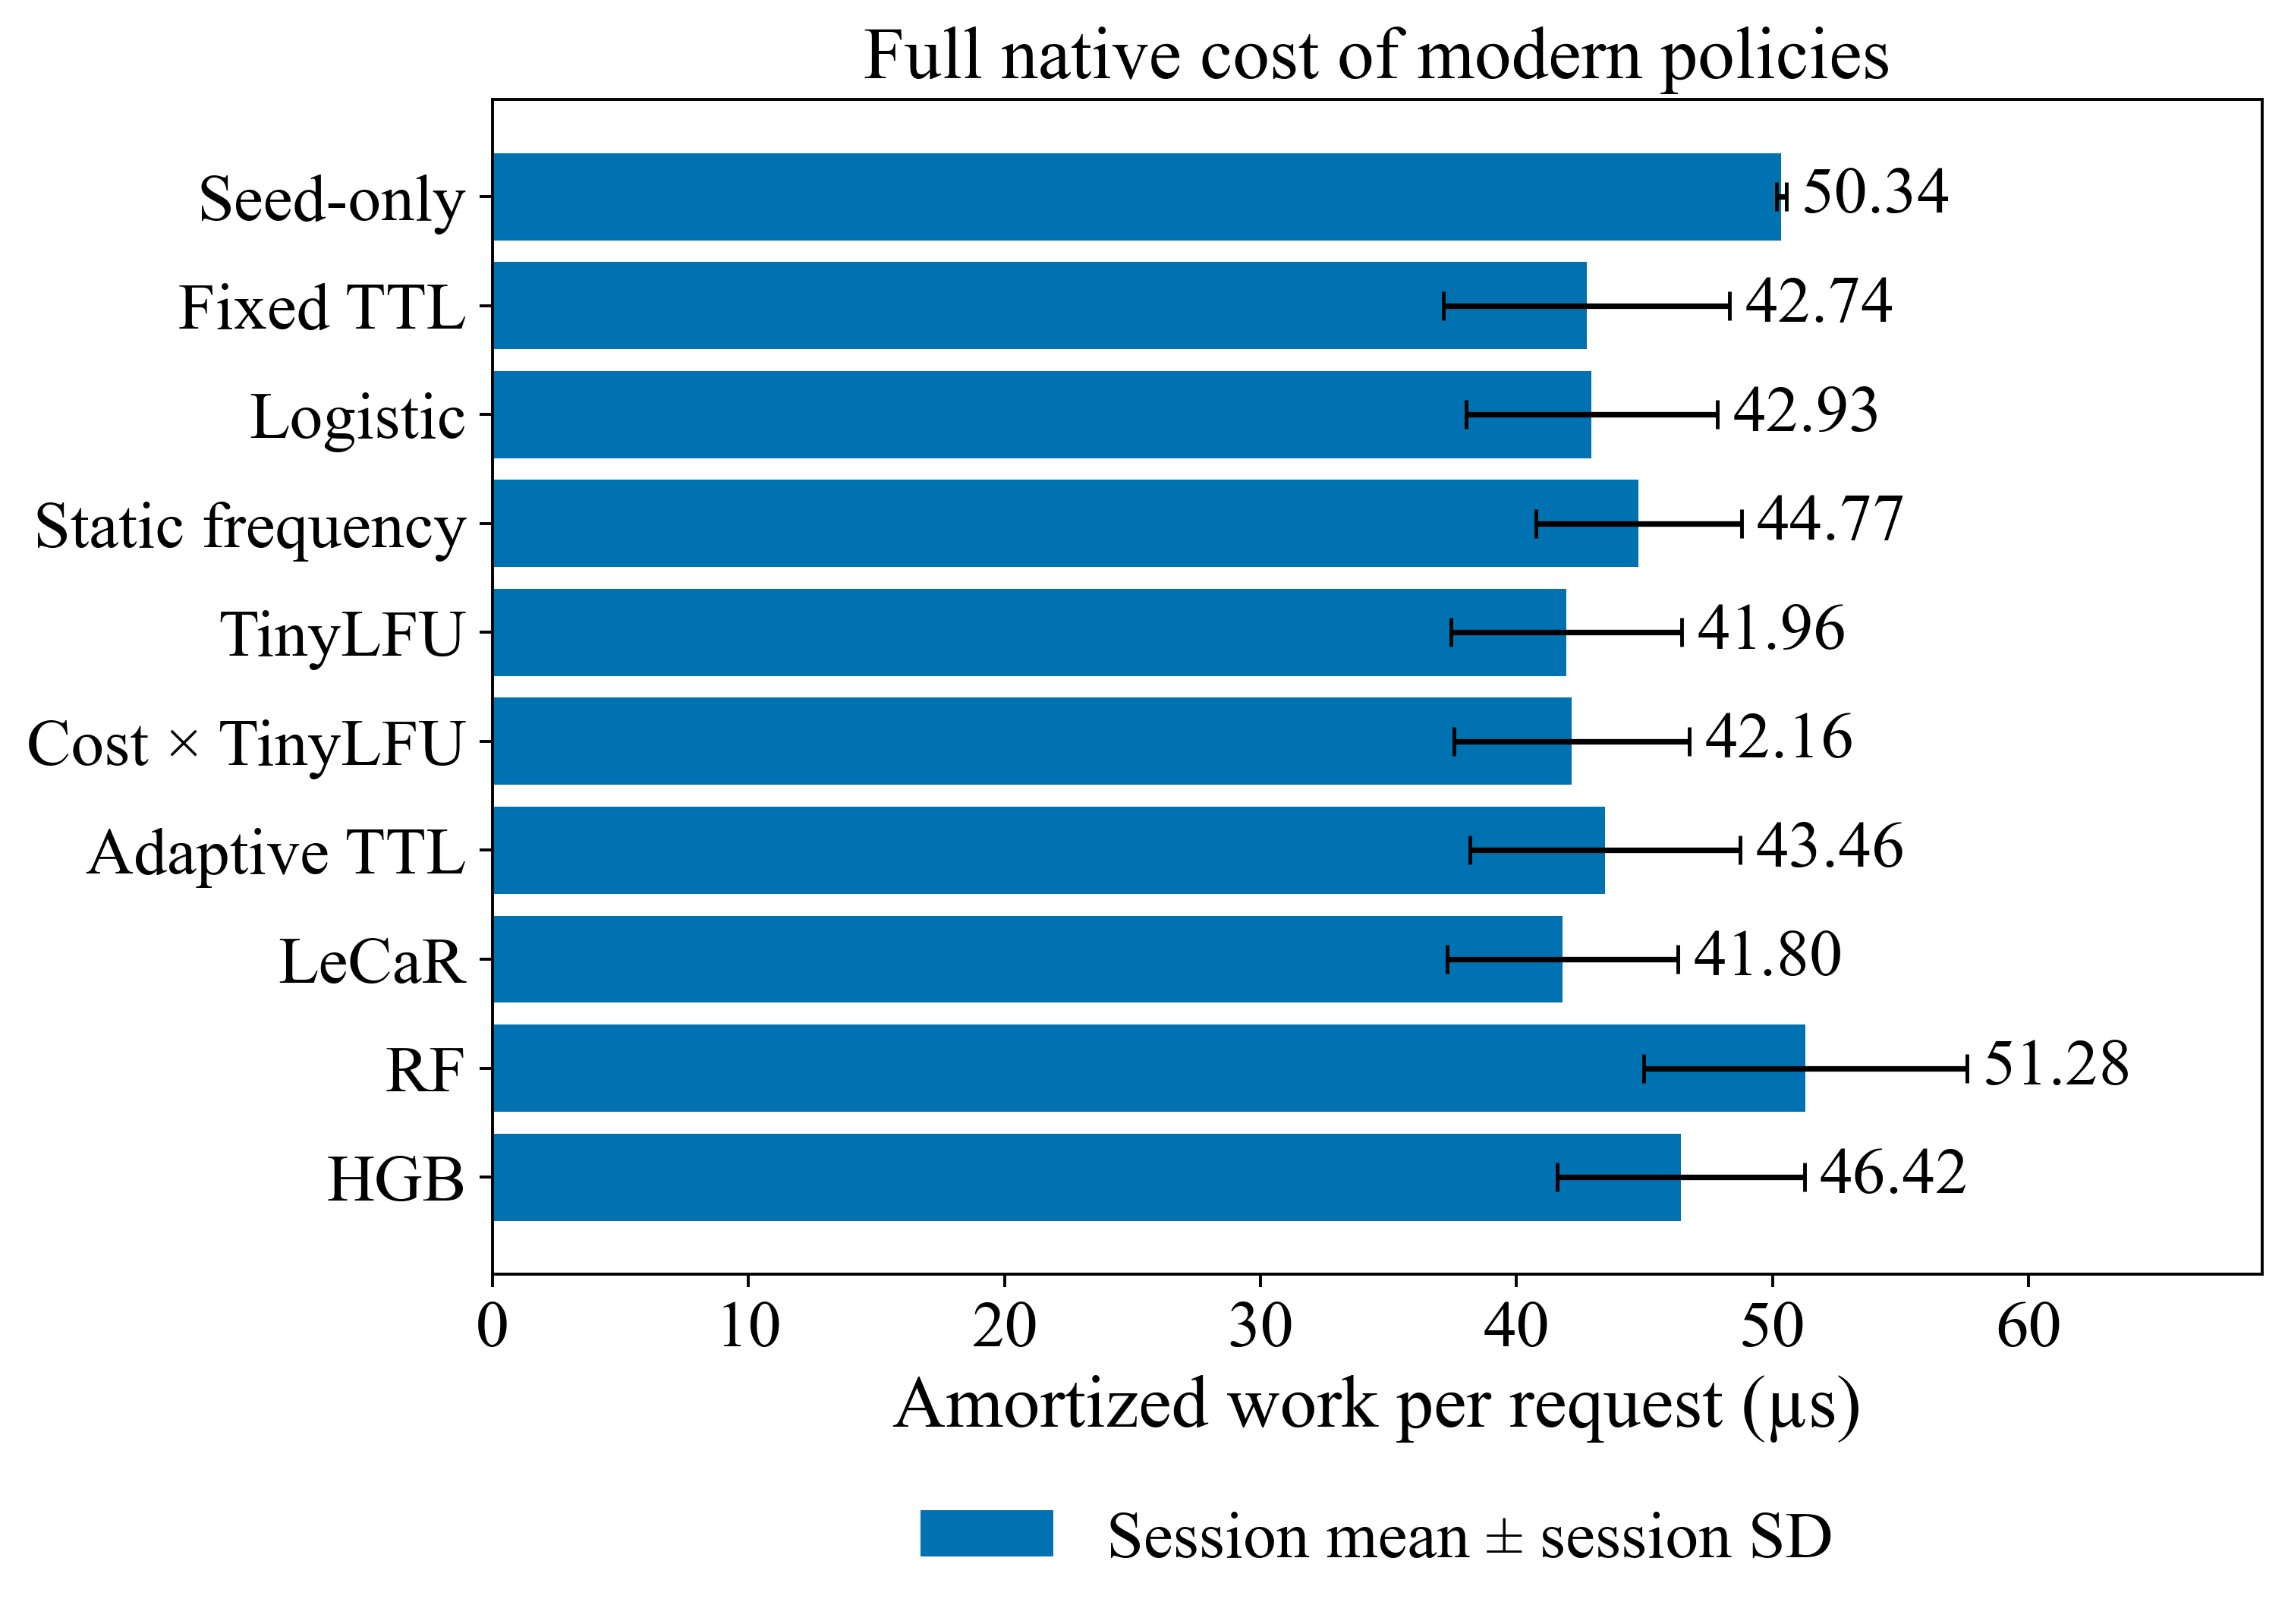

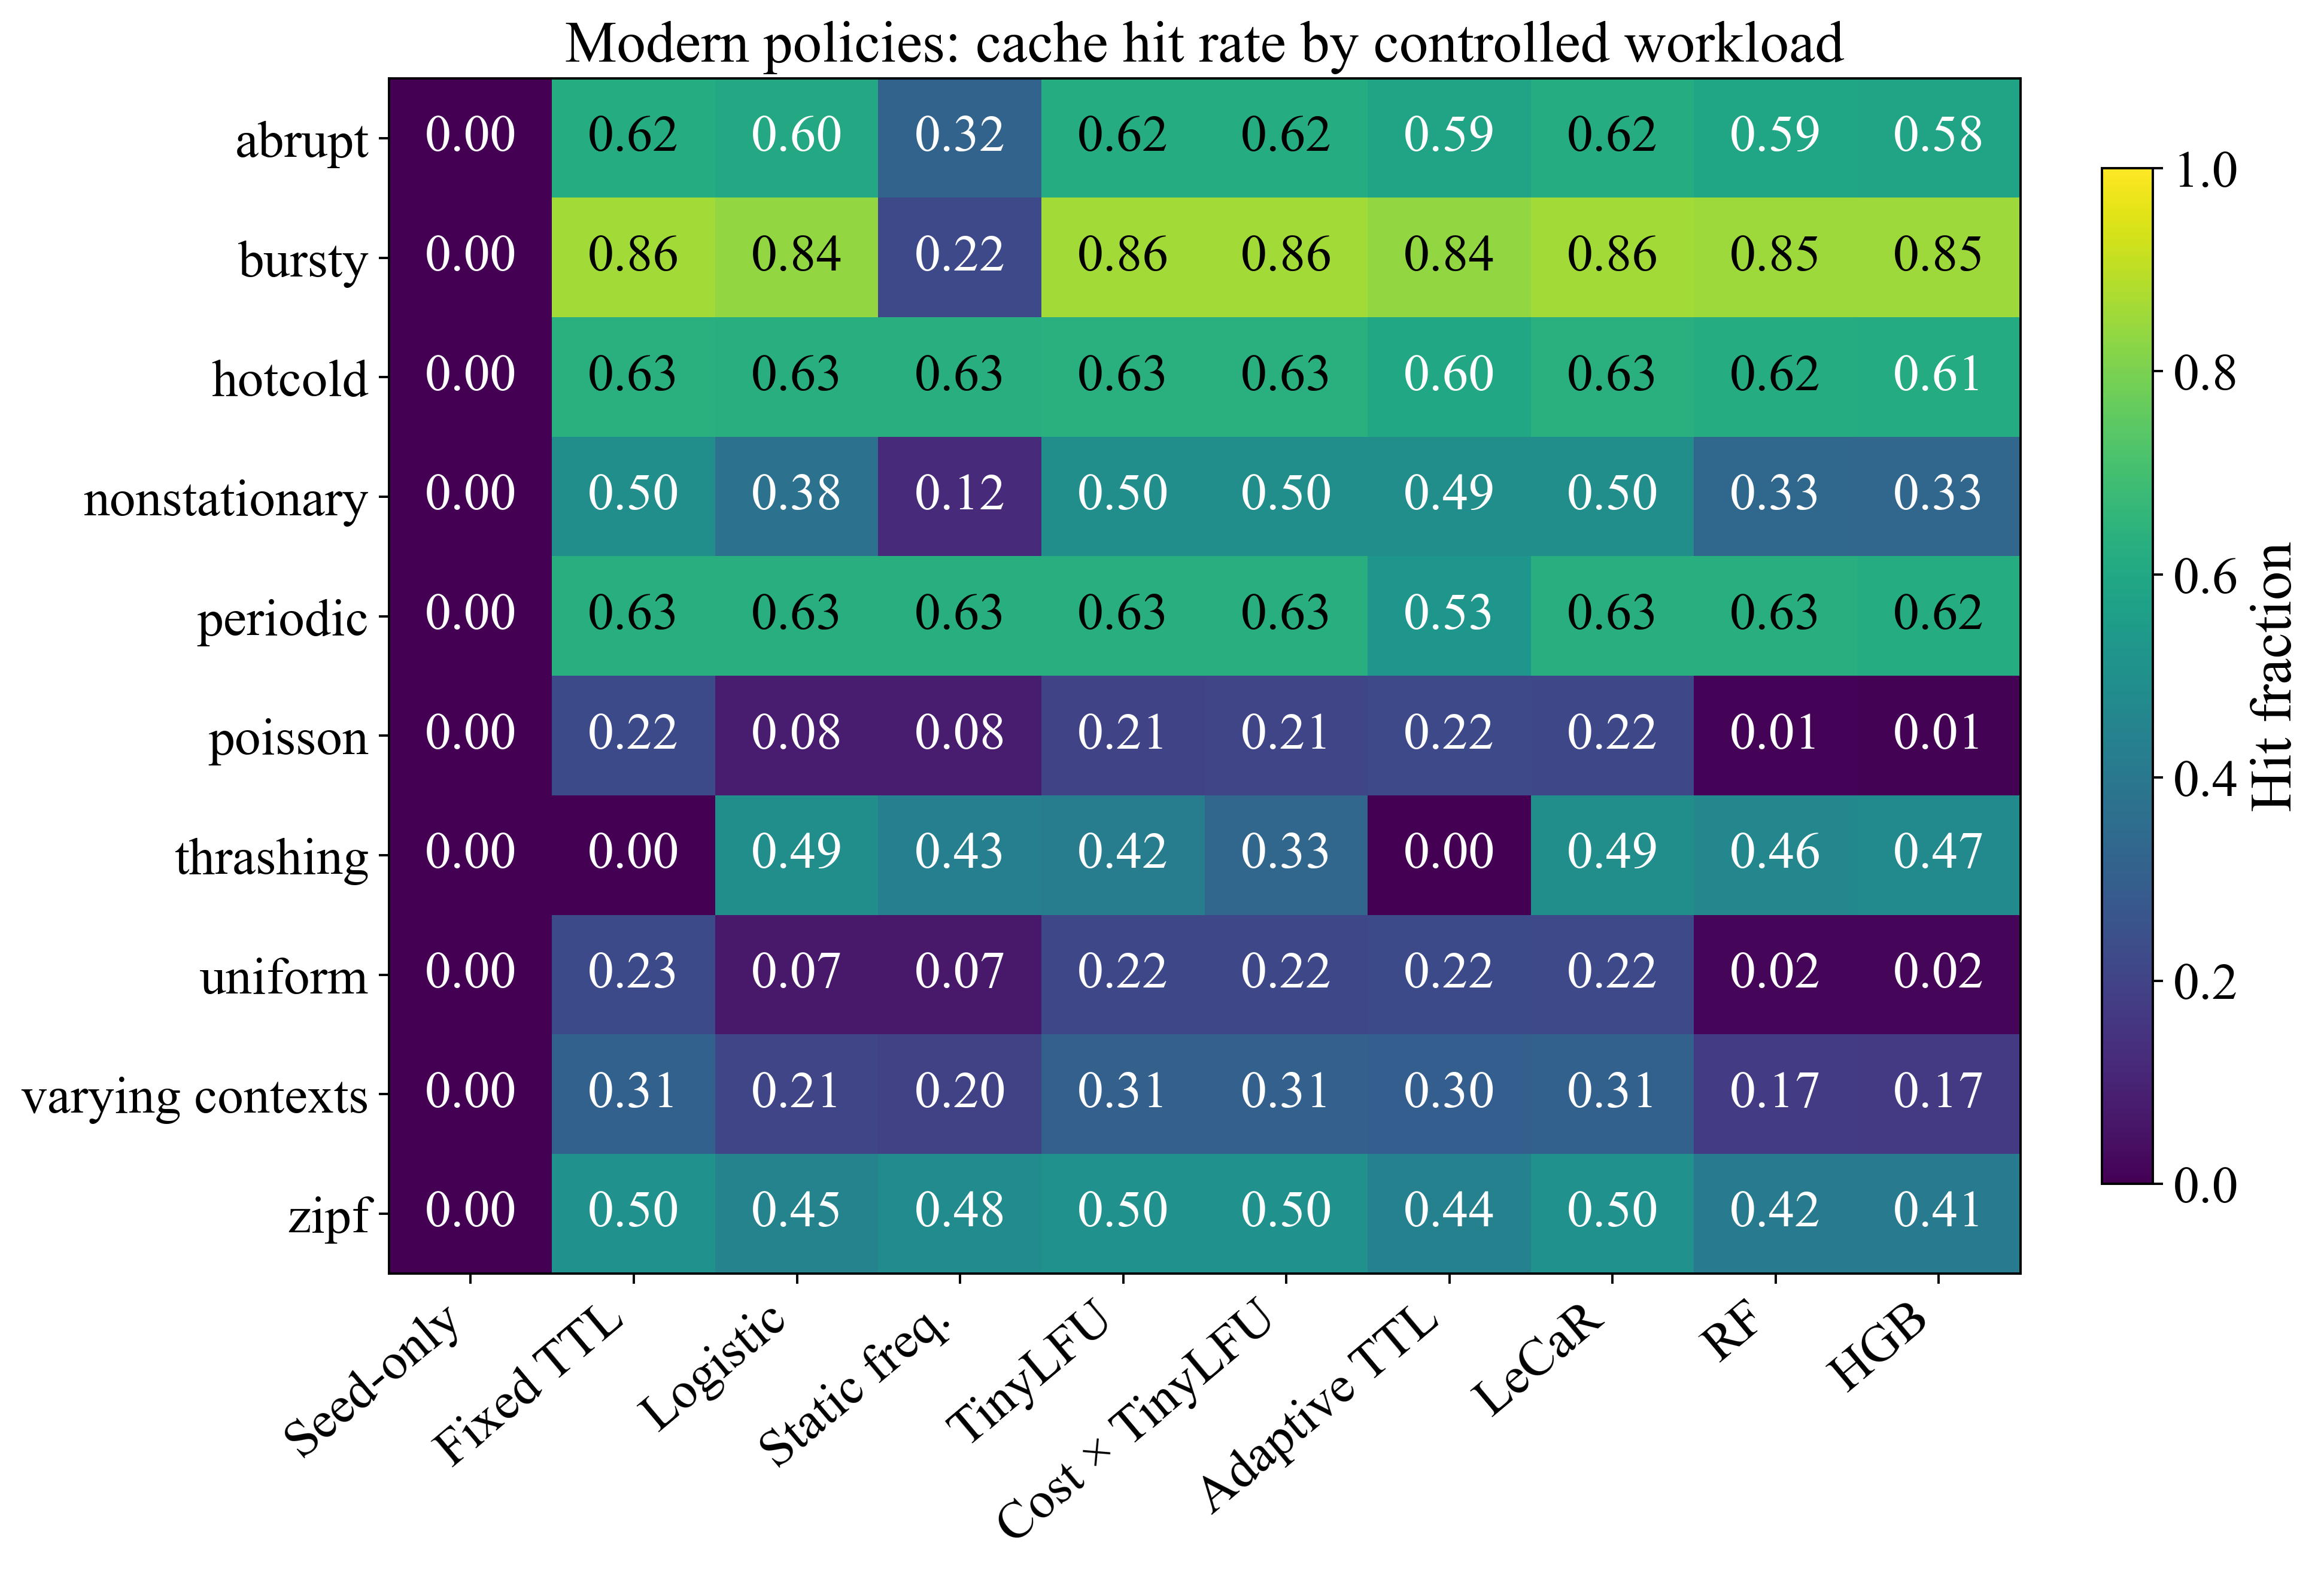

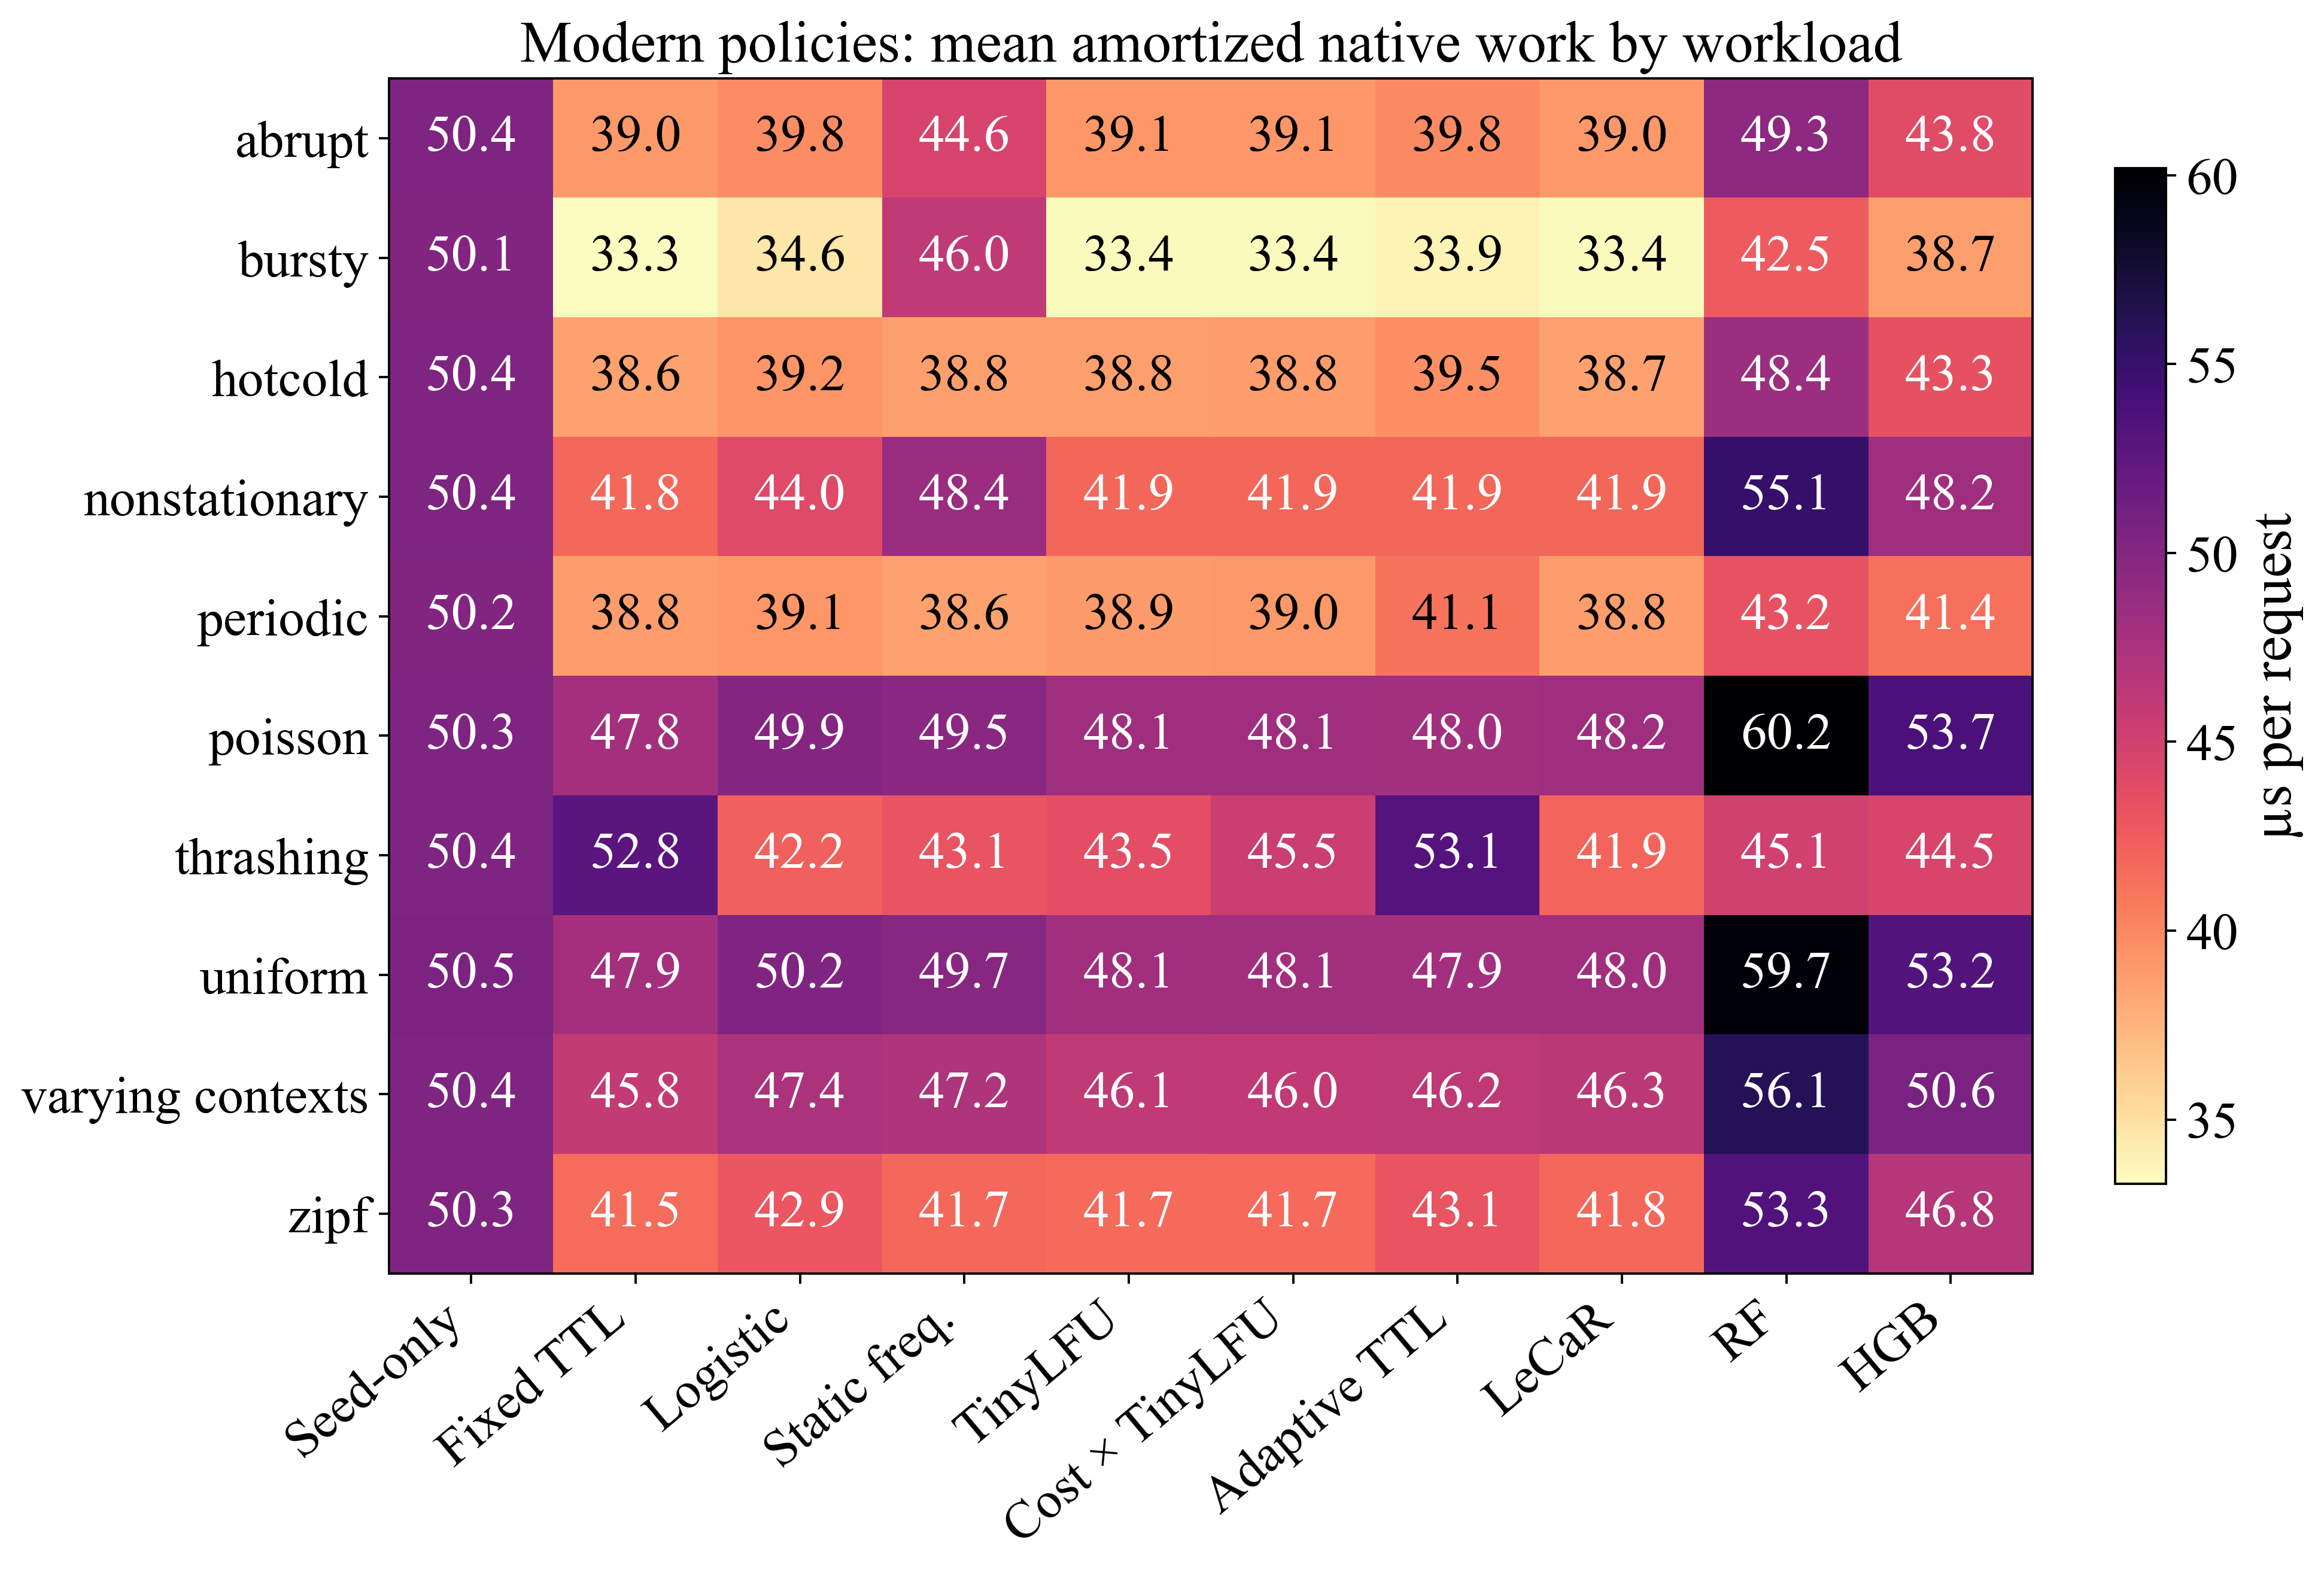

In [13]:
metric_means=native_metrics.groupby("policy").mean(numeric_only=True).reindex(POLICIES)
save_table(metric_means[["hit_rate","miss_rate","reconstructions","service_mean_us","service_p95_us","service_p99_us","amortized_work_us"]],"native_primary_metrics", exclude=['amortized_work_us'])
save_table(metric_means[["response_mean_us","response_p99_us","arrival_throughput_req_s","cycles_mean","prediction_mean_us","idle_maintenance_mean_us"]],"native_response_and_overhead", exclude=['prediction_mean_us'])
save_table(metric_means[["sampled_cache_mean_bytes","cache_max_bytes","expanded_key_byte_seconds","locked_arena_bytes","peak_rss_bytes","evictions","zeroizations"]].rename(columns={"cache_max_bytes":"mean_session_peak_cache_bytes","peak_rss_bytes":"mean_session_peak_rss_bytes"}),"native_memory_and_residency", exclude=['expanded_key_byte_seconds'])
fig,ax=plt.subplots(figsize=(8.5,6.0),layout="constrained")
v=metric_means.amortized_work_us;sd=native_metrics.groupby("policy").amortized_work_us.std().reindex(POLICIES)
bars=ax.barh([LABELS[p] for p in POLICIES],v,xerr=sd,capsize=4,color=COLORS[0],label="Session mean ± session SD")
for y,(value,err) in enumerate(zip(v,sd)):ax.text(value+err+.6,y,f"{value:.2f}",va="center")
ax.set_xlim(0,(v+sd).max()*1.2);ax.invert_yaxis();ax.set_xlabel("Amortized work per request (µs)");ax.set_title("Full native cost of modern policies")
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.15),frameon=False)
save_figure(fig,"native_amortized_work",pd.DataFrame({"Policy":POLICIES,"Mean_us":v.to_numpy(),"SD_us":sd.to_numpy()}))
def annotated_matrix(frame,title,scale_label,name,fmt=".2f",vmin=None,vmax=None,cmap="viridis"):
    values=frame.to_numpy();fig,ax=plt.subplots(figsize=(8.5 if len(frame.columns)<=5 else 11.0,7.4),layout="constrained")
    im=ax.imshow(values,aspect="auto",cmap=cmap,vmin=vmin,vmax=vmax)
    ax.set_xticks(range(len(frame.columns)),[{"static_frequency":"Static freq.","costaware_tiny":"Cost × TinyLFU","adaptive_ttl":"Adaptive TTL"}.get(p,LABELS.get(p,p)) for p in frame.columns],rotation=40,ha="right")
    ax.set_yticks(range(len(frame)),[s.replace("_"," ") for s in frame.index]);ax.set_title(title)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            val=values[i,j];rgba=im.cmap(im.norm(val));lum=.2126*rgba[0]+.7152*rgba[1]+.0722*rgba[2]
            ax.text(j,i,format(val,fmt).replace("-","−"),ha="center",va="center",color="black" if lum>.55 else "white")
    fig.colorbar(im,ax=ax,label=scale_label,shrink=.85)
    save_figure(fig,name,frame.rename_axis("Workload").reset_index())
hit_matrix=native_metrics.pivot_table(index="workload_id",columns="policy",values="hit_rate").reindex(columns=POLICIES)
work_matrix=native_metrics.pivot_table(index="workload_id",columns="policy",values="amortized_work_us").reindex(columns=POLICIES)
annotated_matrix(hit_matrix,"Modern policies: cache hit rate by controlled workload","Hit fraction","native_hit_matrix",vmin=0,vmax=1)
annotated_matrix(work_matrix,"Modern policies: mean amortized native work by workload","µs per request","native_work_matrix",fmt=".1f",cmap="magma_r")

## Парные различия и изменение нагрузки
Внутри каждого из десяти фиксированных семейств повторно выбираем целые парные сессии, сохраняя зависимость политик. 95% bootstrap-интервалы относятся к development-данным, использованным при разработке; это не независимое подтверждение преимущества. Начало и конец сценариев сравниваются описательно, без объявления причинного эффекта drift-механизма.

,Mean_difference_vs_fixed_us,Development_CI_low_us,Development_CI_high_us,Paired_sessions
Policy,,,,
seed_only,7.604749,7.495846,7.720948,30
fixed_ttl,0.000000,0.000000,0.000000,30
logistic,0.196970,0.120670,0.274040,30
static_frequency,2.032414,1.911374,2.171319,30
tiny_lfu,-0.781193,-0.834299,-0.722657,30
costaware_tiny,-0.575680,-0.685461,-0.458227,30
adaptive_ttl,0.723120,0.651983,0.790024,30
lecar,-0.938063,-1.000878,-0.877639,30
rf,8.548511,8.471656,8.625719,30


,Lowest_observed_work_policy,Logistic_minus_best_us,HGB_minus_best_us
workload_id,,,
abrupt,lecar,0.771027,4.786429
bursty,fixed_ttl,1.263616,5.429134
hotcold,fixed_ttl,0.560383,4.666962
nonstationary,fixed_ttl,2.200817,6.365511
periodic,static_frequency,0.507392,2.783564
poisson,fixed_ttl,2.089920,5.866944
thrashing,lecar,0.294797,2.517959
uniform,fixed_ttl,2.350183,5.282837
varying_contexts,fixed_ttl,1.581850,4.780569


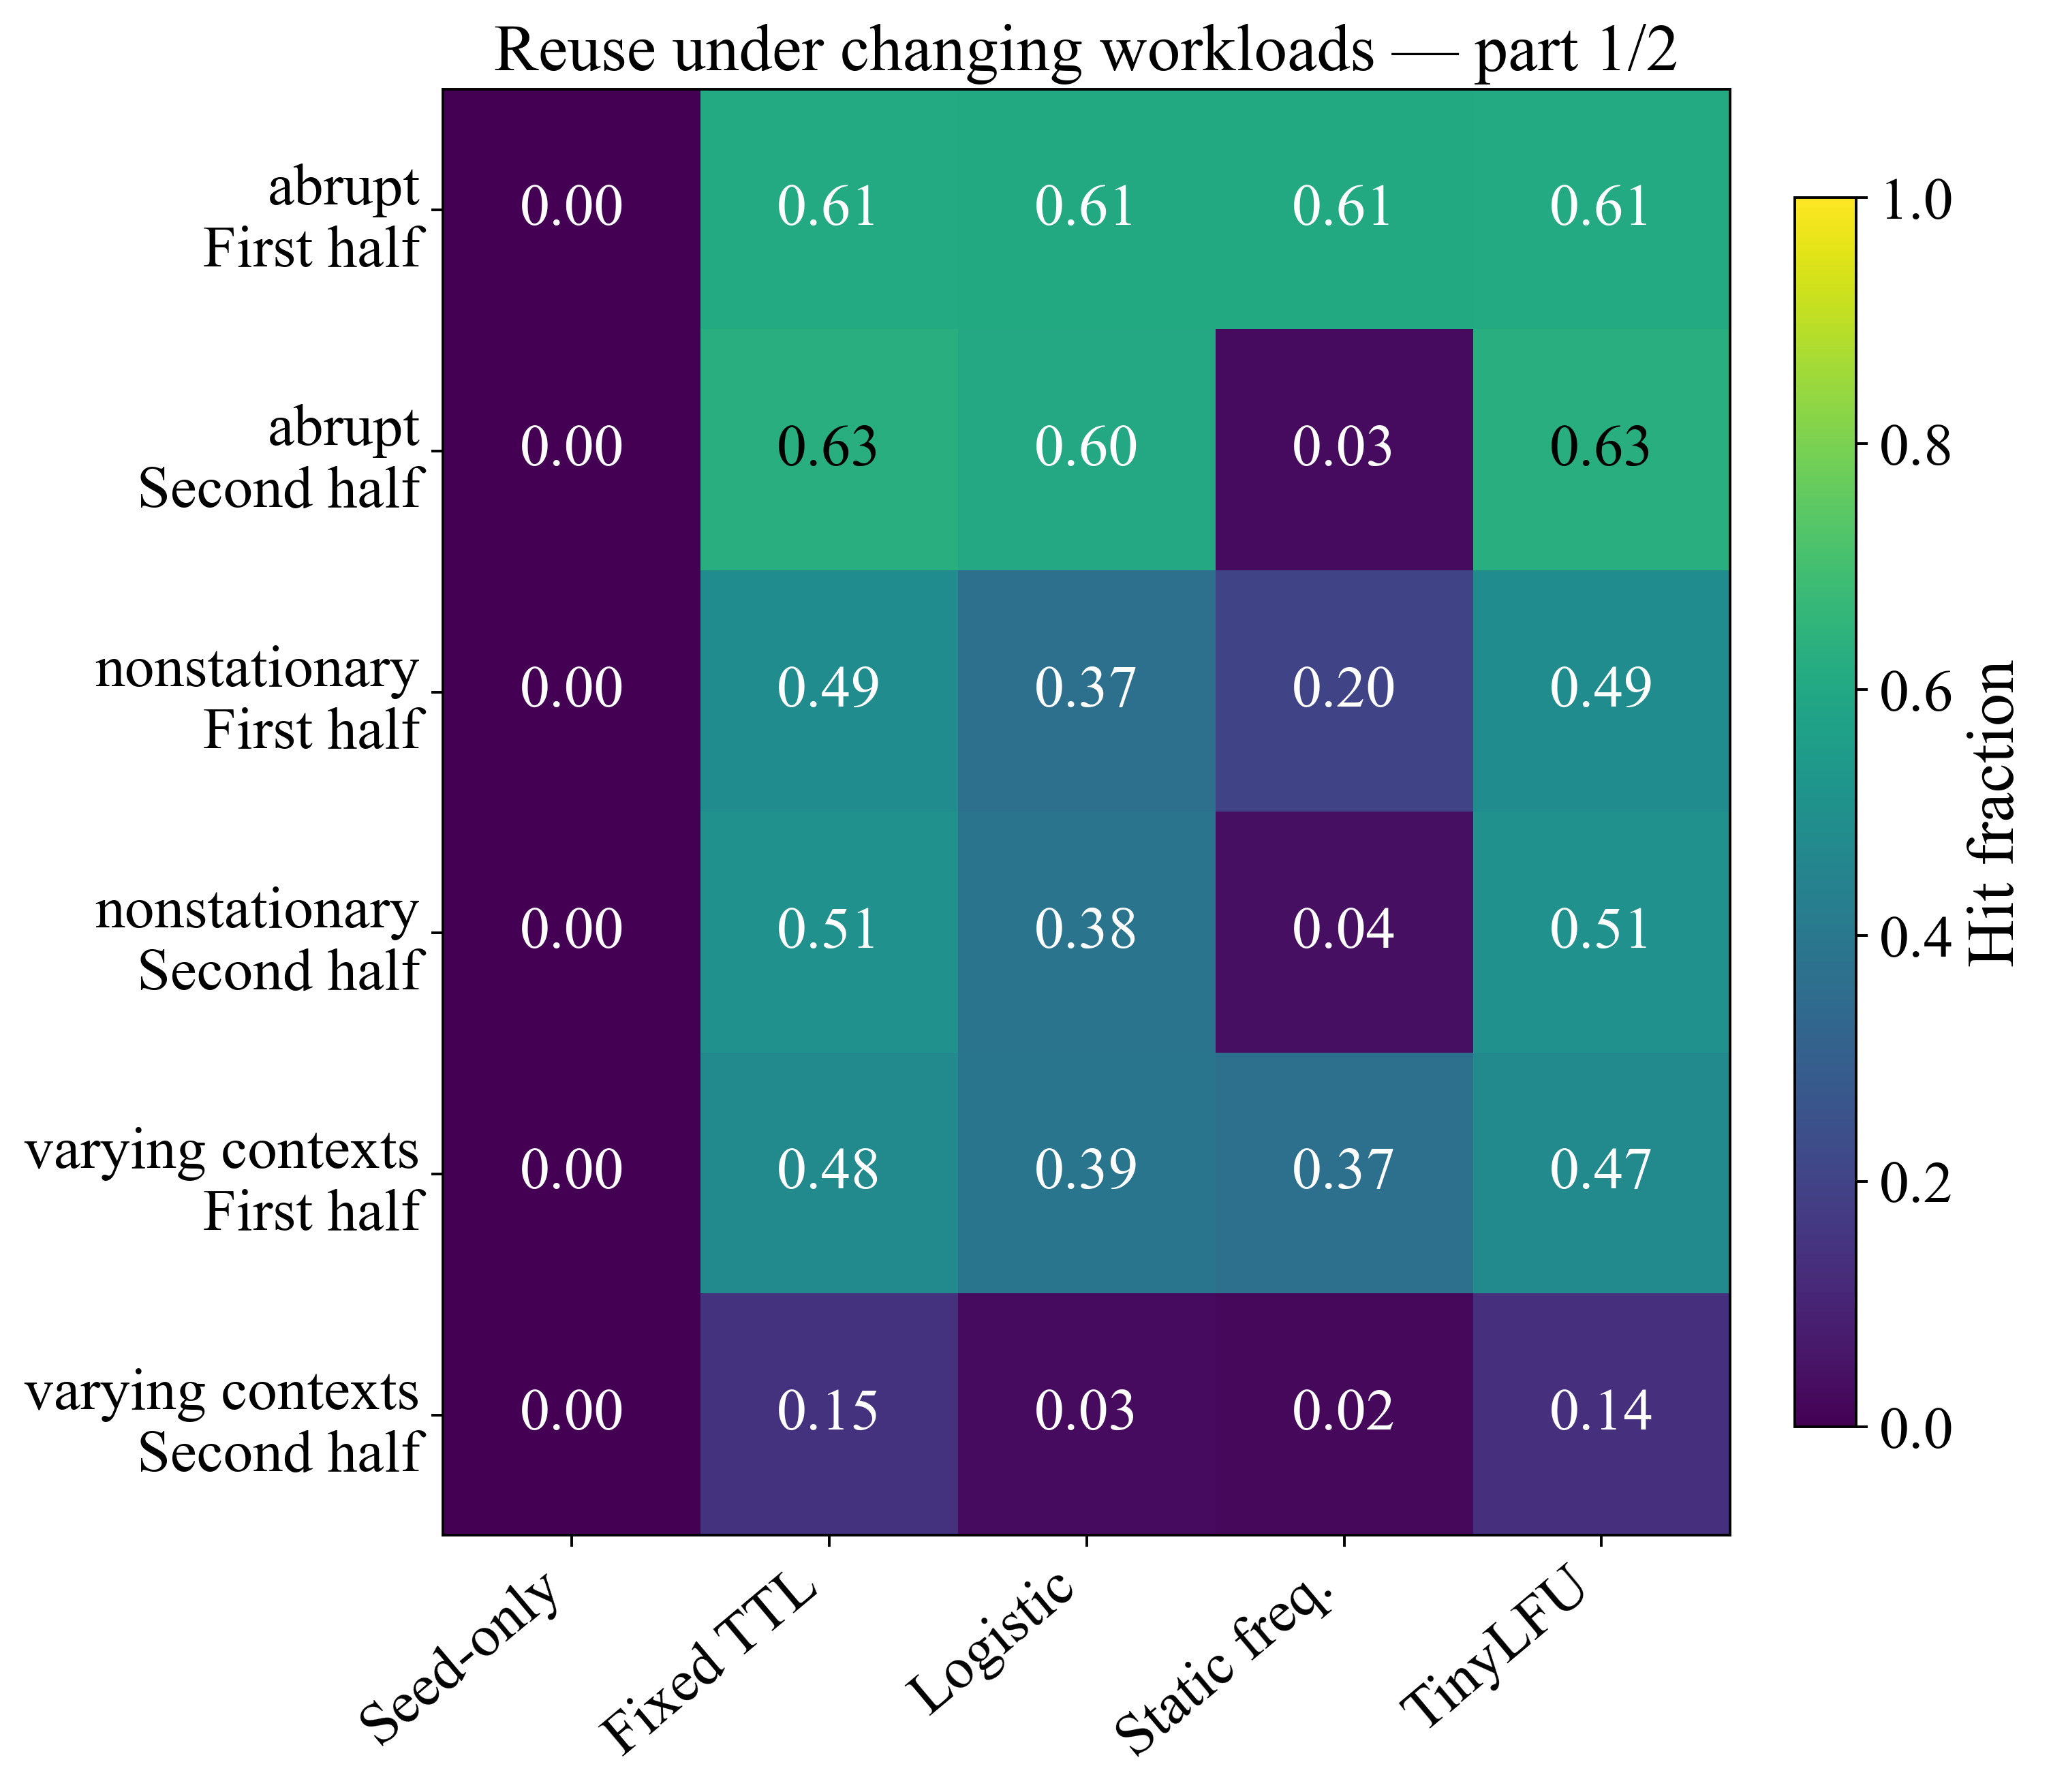

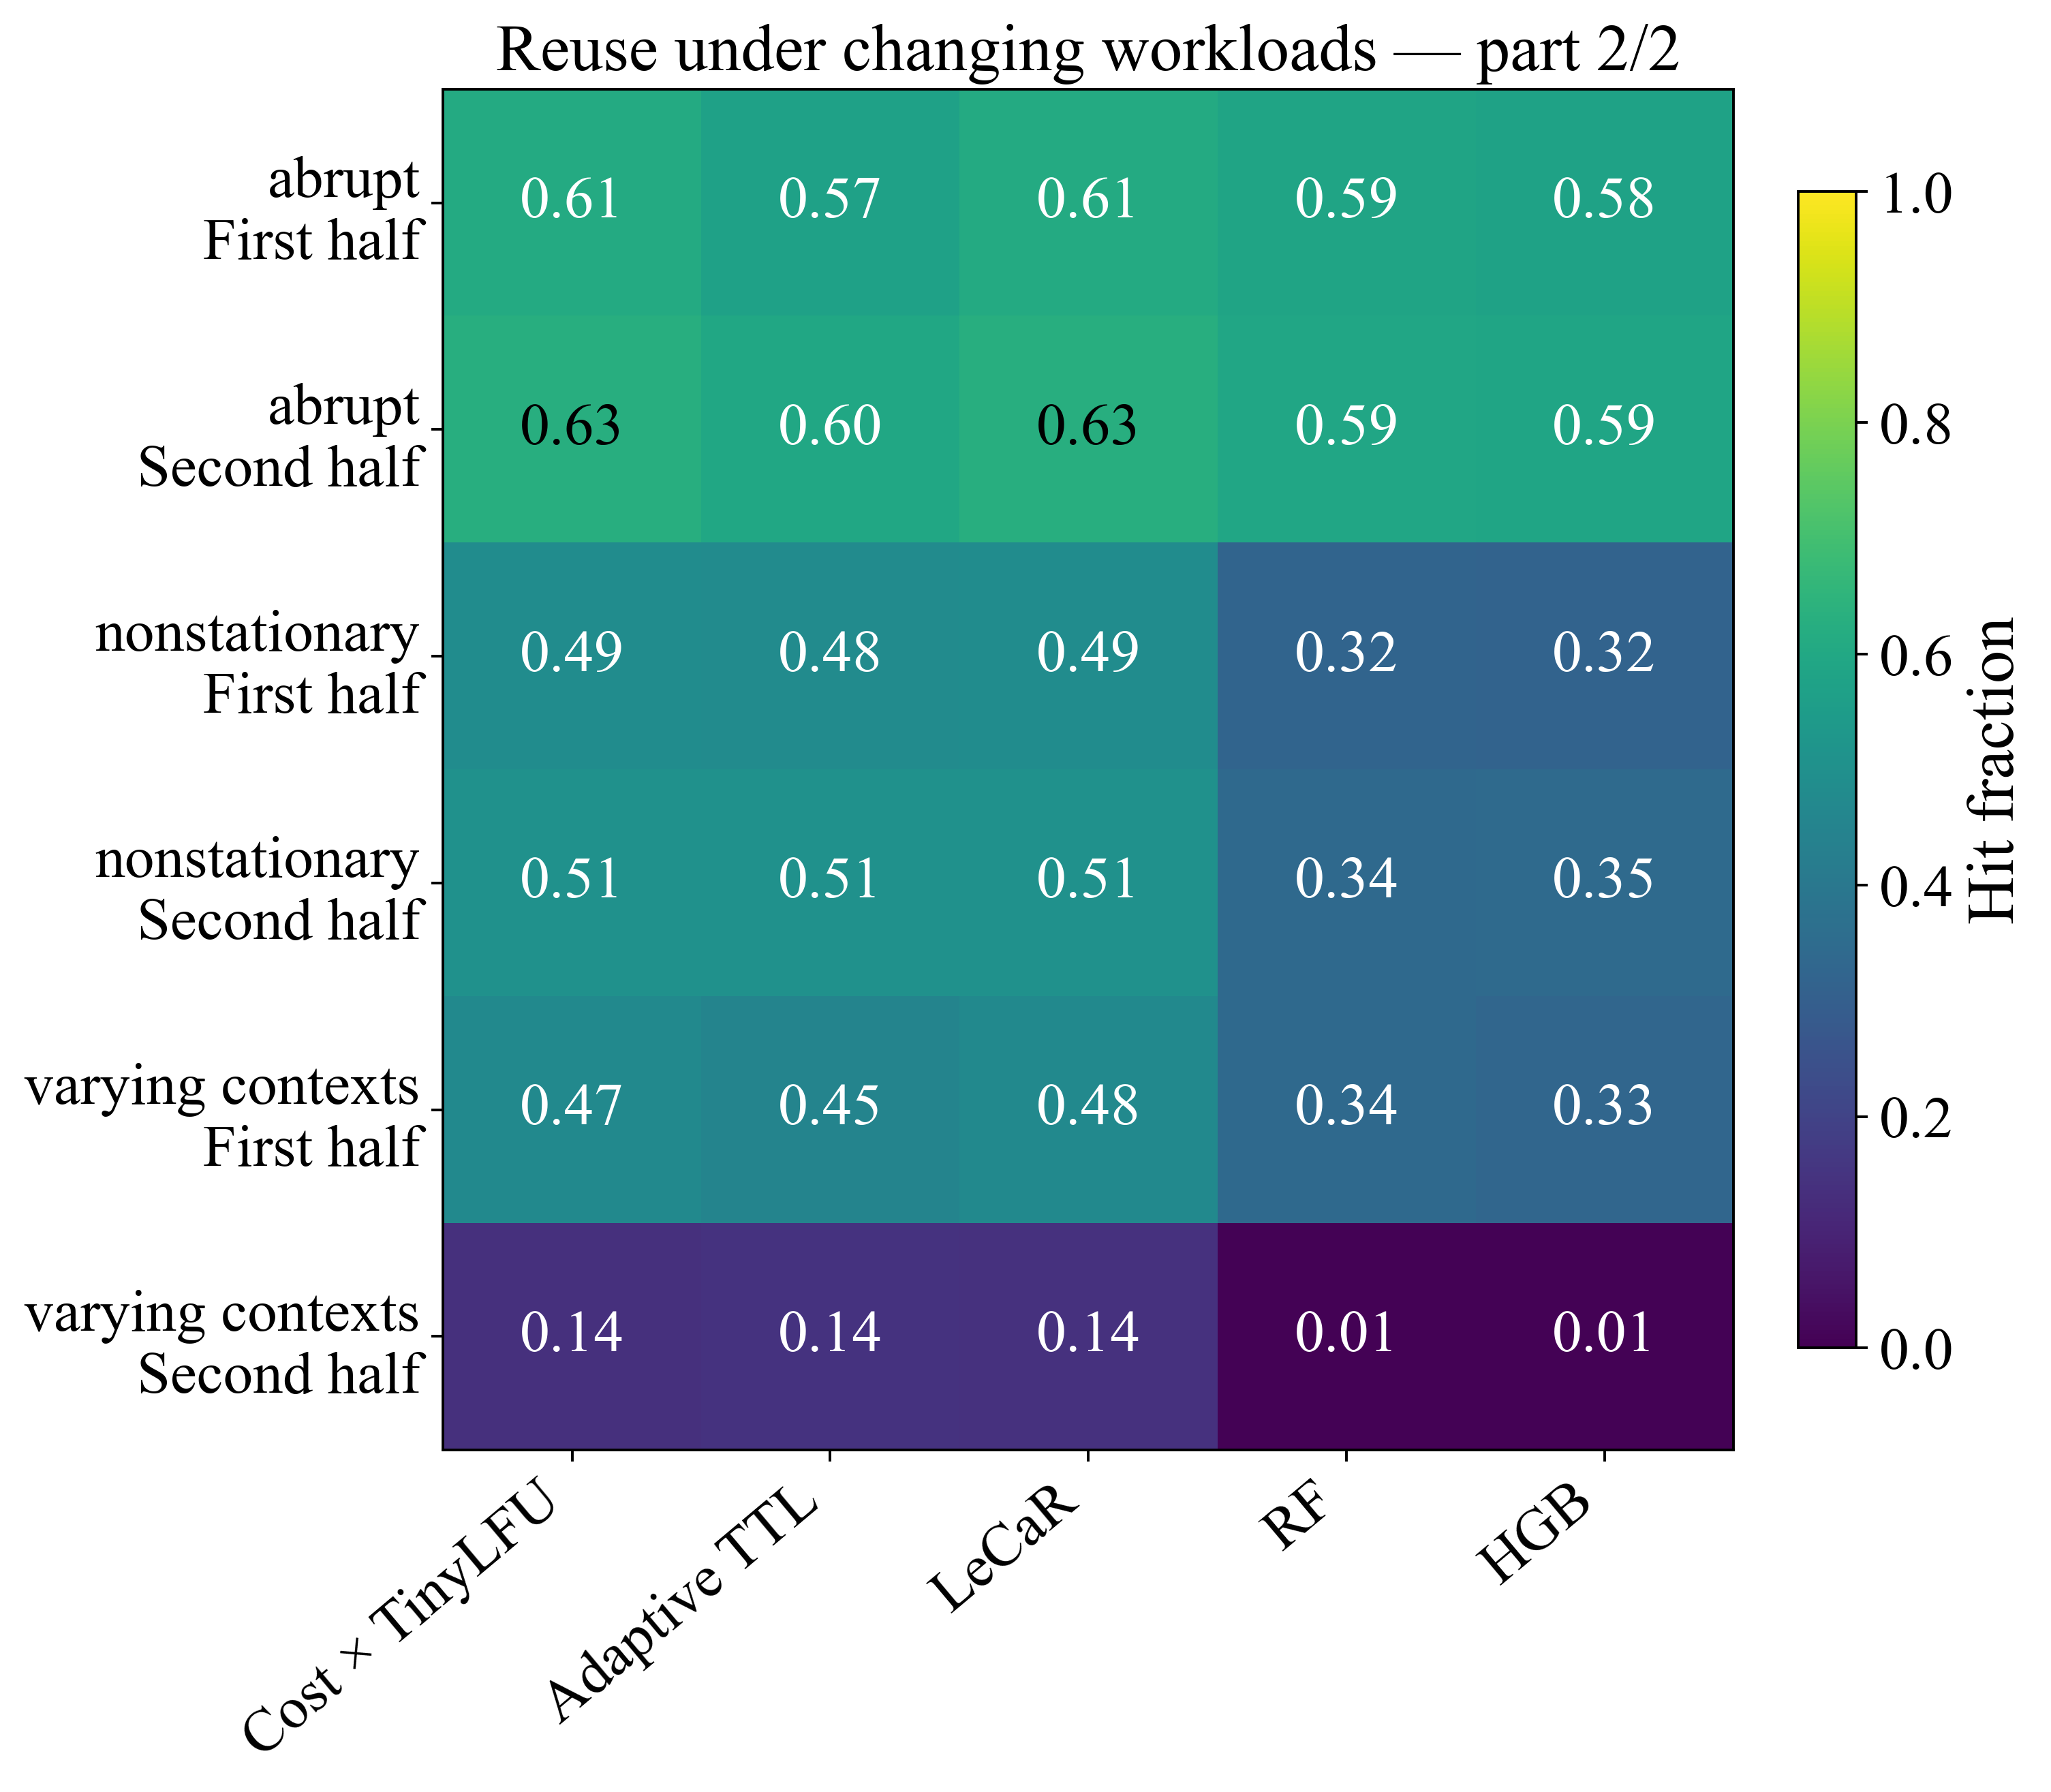

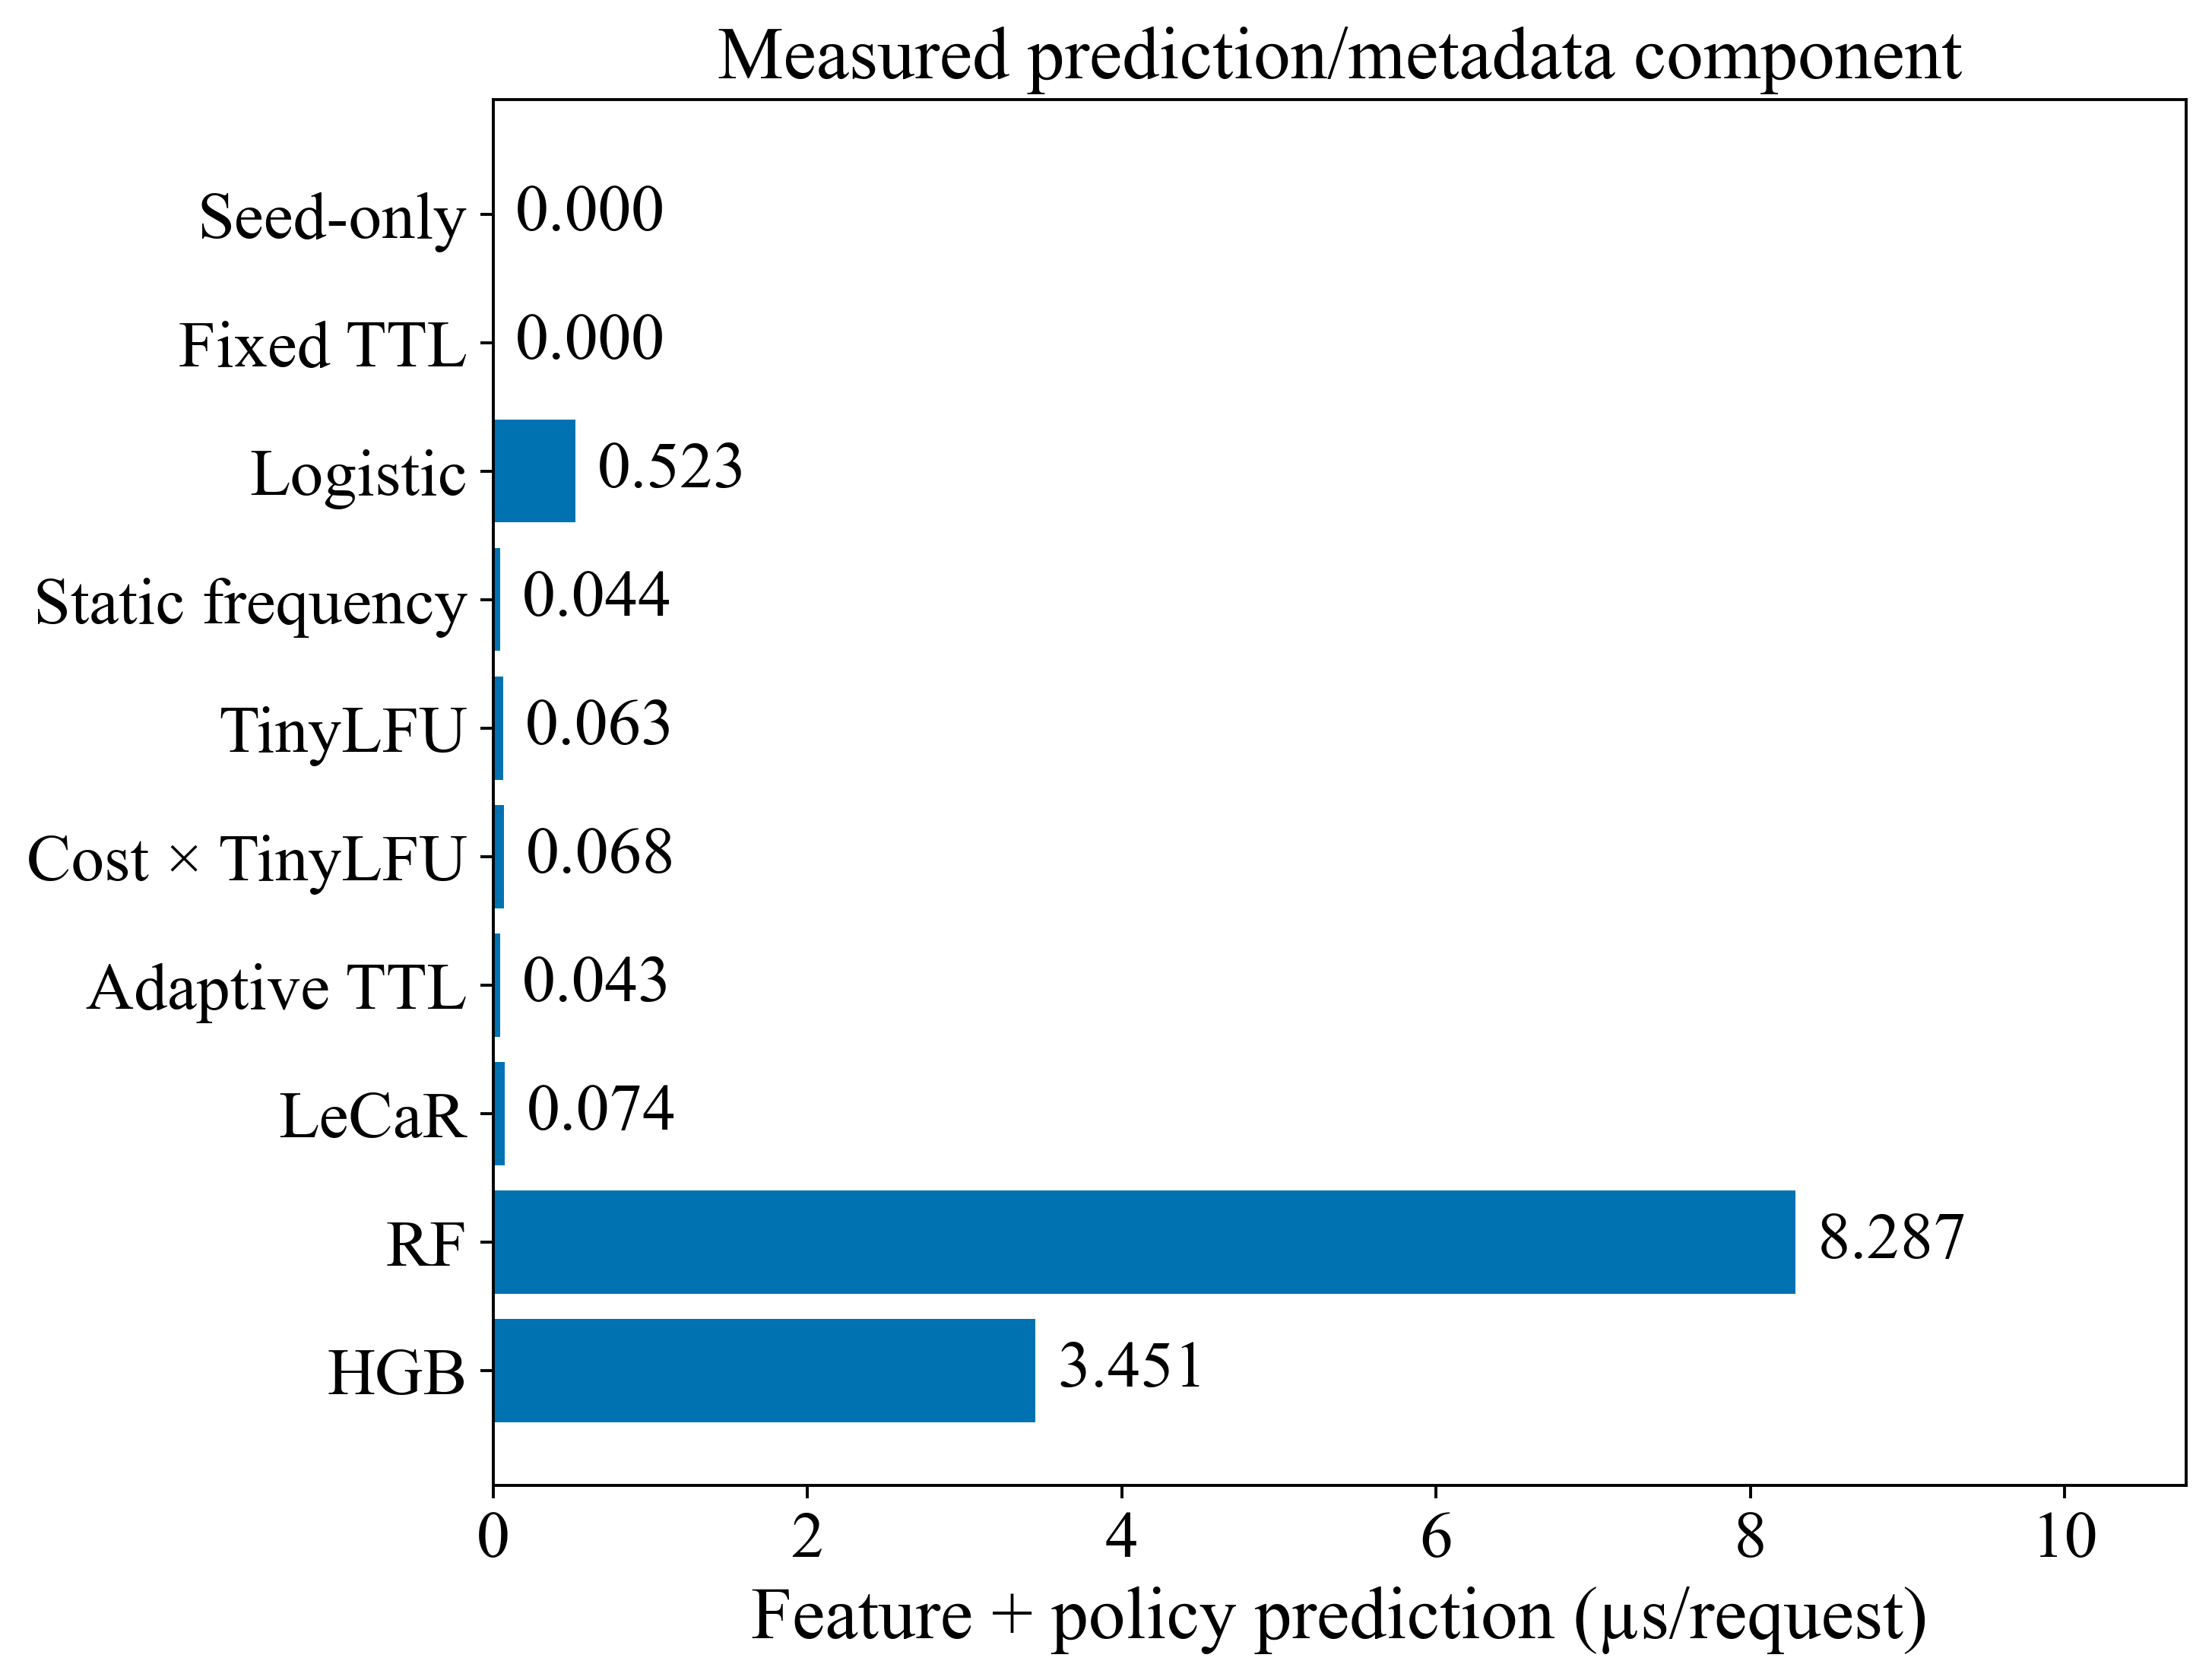

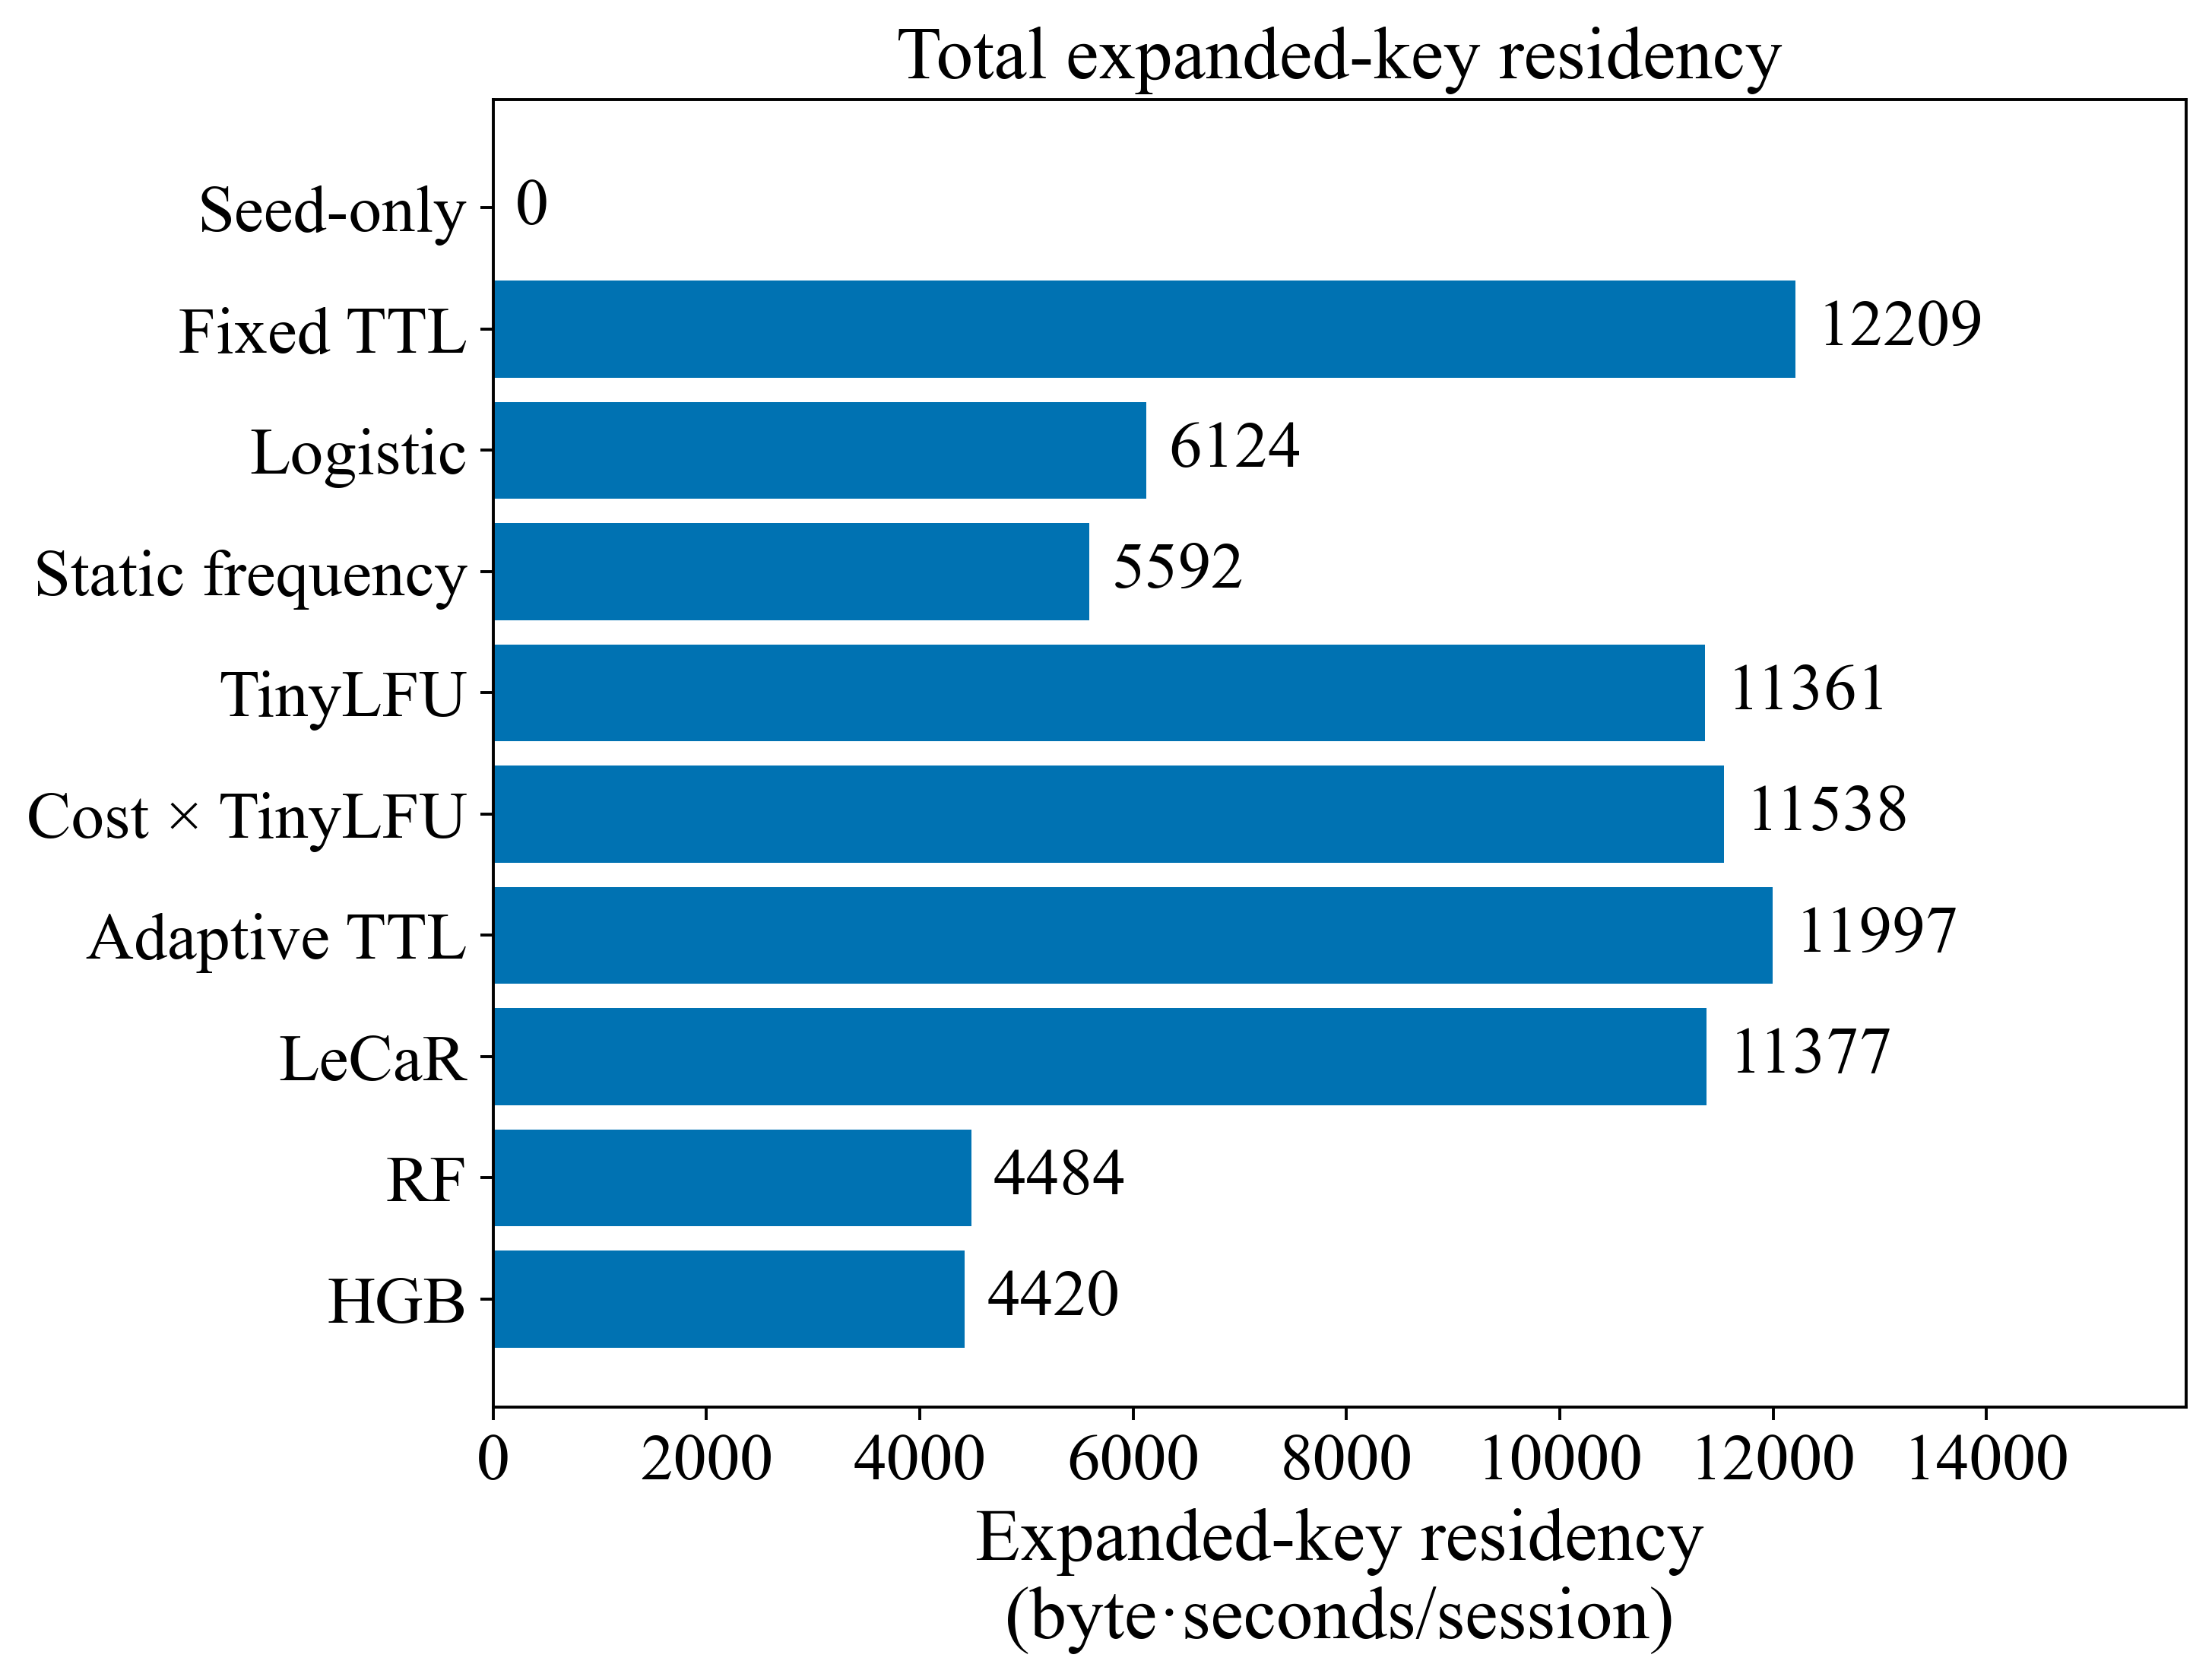

,Session,Policy,Temperature_min_C,Temperature_max_C,Frequency_min_MHz,Frequency_max_MHz,Throttling_flag,Late_clears,Max_lifetime_ms,Max_lateness_us
0,development_bursty_3,tiny_lfu,50.15,52.35,2400.0,2400.0,False,1,10.375482,375.482


In [14]:
# Paired uncertainty and shift diagnostics use independent process sessions.
paired=native_metrics.pivot(index=["workload_id","session_id"],columns="policy",values="amortized_work_us").reindex(columns=POLICIES)
difference=paired.to_numpy()-paired["fixed_ttl"].to_numpy()[:,None]
rng=np.random.default_rng(73104);boot=[];families=paired.index.get_level_values("workload_id").to_numpy()
for repeat in range(2000):
    ids=np.concatenate([rng.choice(np.flatnonzero(families==family),size=3,replace=True) for family in sorted(set(families))])
    boot.append(difference[ids].mean(axis=0))
lo,hi=np.quantile(boot,[.025,.975],axis=0)
paired_summary=pd.DataFrame({"Policy":POLICIES,"Mean_difference_vs_fixed_us":difference.mean(axis=0),"Development_CI_low_us":lo,"Development_CI_high_us":hi,"Paired_sessions":30}).set_index("Policy")
save_table(paired_summary,"paired_modern_work_difference")
regime=work_matrix.idxmin(axis=1).rename("Lowest_observed_work_policy").to_frame()
regime["Work_us"]=work_matrix.min(axis=1)
regime["Logistic_minus_best_us"]=work_matrix.logistic-work_matrix.min(axis=1)
regime["HGB_minus_best_us"]=work_matrix.hgb-work_matrix.min(axis=1)
save_table(regime,"modern_regime_winners", exclude=['Work_us'])
shift_events=native_events.loc[native_events.workload_id.isin(["abrupt","nonstationary","varying_contexts"])].copy()
shift_events["Phase"]=np.where(shift_events.request_id<500,"First half","Second half")
shift_session=shift_events.groupby(["workload_id","session_id","policy","Phase"]).agg(Hit_rate=("cache_hit","mean"),Service_us=("service_ns",lambda x:x.mean()/1000)).reset_index()
shift_mean=shift_session.groupby(["workload_id","Phase","policy"])[["Hit_rate","Service_us"]].mean().reset_index()
save_table(shift_mean.pivot(index=["workload_id","Phase"],columns="policy",values="Hit_rate").reindex(columns=POLICIES),"native_shift_hit_rates", show=False)
shift_matrix=shift_mean.pivot(index=["workload_id","Phase"],columns="policy",values="Hit_rate").reindex(columns=POLICIES)
shift_matrix.index=[f"{family.replace('_',' ')}\n{phase}" for family,phase in shift_matrix.index]
for part,cols in enumerate((POLICIES[:5],POLICIES[5:]),start=1):
    annotated_matrix(shift_matrix.loc[:,cols],f"Reuse under changing workloads — part {part}/2","Hit fraction",f"native_shift_hit_rates_part{part}",vmin=0,vmax=1)

for column,xlabel in zip(["prediction_mean_us","expanded_key_byte_seconds"],["Feature + policy prediction (µs/request)","Expanded-key residency (byte·seconds/session)"]):
    fig,ax=plt.subplots(figsize=(8.2,6.2),layout="constrained")
    vals=metric_means[column];bars=ax.barh([LABELS[p] for p in POLICIES],vals,color=COLORS[0]);ax.bar_label(bars,fmt="%.3f" if column=="prediction_mean_us" else "%.0f",padding=6)
    ax.set_xlim(0,vals.max()*1.3);ax.invert_yaxis();ax.set_xlabel(xlabel)
    ax.set_title("Measured prediction/metadata component" if column=="prediction_mean_us" else "Total expanded-key residency")
    save_figure(fig,"native_"+("prediction_overhead" if column=="prediction_mean_us" else "key_residency"),metric_means[[column]].reset_index())
flagged=quality.loc[quality.Late_clears.gt(0)|quality.Throttling_flag]
save_table(flagged.reset_index(drop=True),"all_flagged_native_runs")


## Итоги и переход к SCAR-MLKEM

**Что установлено на development.** При одинаковом бюджете 16 × 2 400 байт и целевом максимальном сроке 10 мс LeCaR и TinyLFU дали среднюю полную амортизированную стоимость 41,798 и 41,955 мкс/запрос против 42,736 у Fixed TTL. Разница LeCaR с Fixed TTL равна −0,938 мкс, exploratory 95% CI [−1,001; −0,878]. Различия не универсальны: при равномерной/пуассоновской нагрузке Fixed TTL лучше, а при thrashing адаптивное вытеснение особенно полезно. Причину единичных малых разниц между политиками с одинаковым hit rate нельзя приписывать алгоритму без дальнейшей проверки.

**Точность не равна эффективности.** RF/HGB улучшили Brier loss до 0,118656/0,117906 против 0,135993 у Logistic, однако их измеренный feature+inference компонент составляет 8,287/3,451 мкс против 0,523 мкс. Их полная стоимость 51,285/46,416 мкс выше 42,933 мкс у Logistic. Изолированно лучший предиктор нельзя объявлять лучшим контроллером. Почти идеальный прогноз для детерминированного thrashing не доказывает применимость к реальному эксплуатационному трафику.

**Компромисс удержания.** У Logistic средняя суммарная экспозиция развёрнутых ключей составляет 6 124 byte·s/сессию против 11 377 у LeCaR. Это измеренная площадь «активные байты × время», а не доказательство криптографической безопасности. Seed остаётся секретным и присутствует в locked memory. Единый executable содержит несколько моделей; указанный RSS нельзя трактовать как изолированный размер одной модели. Размеры параметров и фактическая arena показаны отдельно.

**Сдвиги.** Статическая политика теряет hit rate с 0,609 до 0,028 после смены горячего набора abrupt; её frozen prefix не адаптируется. У более точных деревьев низкая частота ложных допусков сопровождается низким hit rate в uniform/poisson. Это мотивирует проверку управляемого компромисса стоимости допуска и удержания, а не обязательное усложнение ML.

**Операционные ограничения.** Все 300 000 декапсуляций правильны, бюджет активного кэша не превышен, throttling-флаги отсутствуют, частота 2 400 MHz, температура 48,50–55,10 °C. В development_bursty_3/TinyLFU зафиксирована одна поздняя очистка: максимальное время 10,375482 мс, превышение 375,482 мкс. Этот запуск сохранён. Защитный запас 200 мкс не превращает Linux в систему жёсткого реального времени; отсутствие нарушений у других политик в этой серии не является гарантией.

**Проверяемая гипотеза следующего этапа.** Лёгкий причинный прогноз с явной ценой удержания, выбором допуска и срока жизни, контролем сдвига и fallback может дать полезный Pareto-компромисс полной задержки и времени хранения. Отдельные механизмы уже известны; научная новизна комбинации ещё не доказана. Каждый компонент должен пройти абляцию. Более дорогой HGB сохраняется как отрицательный/альтернативный компонент, а не объявляется обязательной основой.

Сравнения условны относительно одной платы, десяти сконструированных нагрузок и коротких сессий. Ни новые seed, ни повторные процессы не создают независимые устройства. Нет измерений энергии, нет производственных ML-KEM key-access traces и нет заявления о FIPS/side-channel сертификации. Закрытый тест не создан и не использован.